# 🏥 의료보험 청구비용 회귀분석 — '흡연 × 비만' 상호작용을 찾기까지

> 가입자 1,338명의 데이터로 **품질 점검 → EDA → 전처리 조합 비교 → 도메인 파생변수 모델**을 하나의 흐름으로 수행했습니다.
> 기계적 전처리만으로는 R² 0.75에 머물렀지만, EDA에서 발견한 **'흡연자 중 비만인 사람만 비용이 두 배로 뛴다'** 는 구조를 변수로 만들자 **R² 0.864, RMSE −26%** 로 개선됐습니다.

| 항목 | 내용 |
|---|---|
| **데이터** | Medical Insurance · 1,338행 → 중복 1행 제거 후 1,337행 × 7개 변수 |
| **종속변수** | `charges` 연간 의료보험 청구비용 ($) |
| **분석 질문** | ① 청구비용을 결정하는 요인은? ② 로그변환은 항상 도움이 되는가? ③ 흡연과 비만은 따로 작용하는가, 함께 작용하는가? |
| **주요 기법** | Spearman 상관 · Mann-Whitney U · Welch ANOVA · Games-Howell · 상호작용 파생변수 · 후진소거 OLS |

### 📑 목차
0. **준비** — 라이브러리, 데이터 로드(1회), 분석 설정
1. **PART 1. 데이터 품질 점검** — `my_qtcheck`
2. **PART 2. EDA** — 단변량 → 이변량 → 다변량 · 상호작용 탐색
3. **PART 3. 회귀모델링** — 전처리 체크포인트 비교 → 도메인 파생변수 모델 → 최종 보고
4. **📌 종합 인사이트**

> ⚙️ **사용 모듈** : `my_qtcheck` · `my_plot` · `my_stats` · `my_prep` · `my_ols` (helpers) · 데이터 로더 `jussam`

---
# 0. 준비

### (1) 라이브러리 참조

In [77]:
# ----- 라이브러리 참조
import numpy as np
from pandas import DataFrame, concat, set_option
from IPython.display import display, Markdown

from jussam import load_data      # 실습 데이터 로더
from helpers import *             # my_qtcheck · my_plot · my_stats · my_prep · my_ols

# ----- 출력 형식 (소수점 3자리, 컬럼 생략 없이)
set_option("display.float_format", "{:,.3f}".format)
set_option("display.max_columns", 50)

### (2) 데이터 로드

In [78]:
origin = load_data("insurance")
print(f'데이터 크기: {origin.shape}')
origin.head()

📚 개인의 나이·성별·BMI·흡연 여부·거주 지역 등 기본 건강·인구학적 정보를 바탕으로 의료보험 청구 비용(charges)을 예측하도록 구성된, 선형회귀와 머신러닝 실습에 널리 사용되는 대표적인 보험 비용 데이터셋 (출처: https://www.kaggle.com/datasets/mirichoi0218/insurance)

    field     description
--  --------  --------------------------------------------------------------
 0  age       가입자의 나이(세)
 1  sex       성별 (male, female)
 2  bmi       체질량 지수(Body Mass Index)
 3  children  부양 자녀 수(보험 내 자녀 수)
 4  smoker    흡연 여부 (yes / no)
 5  region    미국 내 거주 지역 (northeast, northwest, southeast, southwest)
 6  charges   의료보험 청구 비용(달러). 예측해야 하는 타깃 변수.

데이터 크기: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,"16,884.924"
1,18,male,33.770,1,no,southeast,"1,725.552"
2,28,male,33.000,3,no,southeast,"4,449.462"
3,33,male,22.705,0,no,northwest,"21,984.471"
4,32,male,28.880,0,no,northwest,"3,866.855"


### (3) 분석 설정

In [79]:
target = "charges"                          # 종속변수
as_category = ["sex", "smoker", "region"]   # 명목형으로 지정할 컬럼

column_means = {
    "age": "나이", "sex": "성별", "bmi": "체질량지수", "children": "부양자녀수",
    "smoker": "흡연여부", "region": "거주지역", "charges": "청구비용($)",
}

---
# PART 1. 데이터 품질 점검

### (1) 자료형 변환

In [80]:
df = my_qtcheck.set_type(data=origin, as_category=as_category)

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       1338 non-null   int32   
 1   sex       1338 non-null   category
 2   bmi       1338 non-null   float32 
 3   children  1338 non-null   int32   
 4   smoker    1338 non-null   category
 5   region    1338 non-null   category
 6   charges   1338 non-null   float32 
dtypes: category(3), float32(2), int32(2)
memory usage: 25.1 KB


### (2) 중복 · 결측치 점검

- 이 데이터에는 개인 식별자가 없어서, **모든 값이 같은 행은 같은 사람이 두 번 기록된 것**으로 보고 제거한다.

In [81]:
df = my_qtcheck.check_duplicates(data=df)
my_qtcheck.check_missing_values(data=df)

중복된 행의 수: 1
중복된 행이 제거되었습니다.


,Missing Count,Missing Ratio (%)
age,0,0.000
sex,0,0.000
bmi,0,0.000
children,0,0.000
smoker,0,0.000
region,0,0.000
charges,0,0.000


### (3) 명목형 변수 기술통계

In [82]:
cat_desc = my_qtcheck.categorical_summary(data=df)
cat_desc

컬럼 'sex'의 value_counts( ):


,count
sex,
female,662
male,675


컬럼 'smoker'의 value_counts( ):


,count
smoker,
no,1063
yes,274


컬럼 'region'의 value_counts( ):


,count
region,
northeast,324
northwest,324
southeast,364
southwest,325


,sex,smoker,region
count,1337,1337,1337
unique,2,2,4
top,male,no,southeast
freq,675,1063,364


### (4) 연속형 변수 기술통계 · 이상치 · 왜도/첨도 · 로그변환 판정

In [83]:
num_desc = my_qtcheck.numerical_summary(data=df)
num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,total_outliers,total_outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
age,"1,337.000",39.222,14.044,18.000,27.000,39.000,51.000,64.000,0.006,similar,24.000,87.000,-9.000,0,0.000,0,0.000,0,0.000,0.055,symmetric,-1.244,platykurtic,none
bmi,"1,337.000",30.663,6.100,15.960,26.290,30.400,34.700,53.130,0.009,similar,8.410,47.315,13.675,9,0.007,0,0.000,9,0.007,0.284,symmetric,-0.053,platykurtic,none
children,"1,337.000",1.096,1.206,0.000,0.000,1.000,2.000,5.000,0.096,similar,2.000,5.000,-3.000,0,0.000,0,0.000,0,0.000,0.937,right tail,0.201,leptokurtic,log1p
charges,"1,337.000","13,279.122","12,110.359","1,121.874","4,746.344","9,386.161","16,657.717","63,770.430",0.415,diff,"11,911.373","34,524.776","-13,120.715",139,0.104,0,0.000,139,0.104,1.515,right tail,1.604,leptokurtic,log


> 💡 **인사이트 — 품질 점검**
>
> - 결측치는 없고, **모든 값이 같은 행 1건을 제거**해 1,337행이 됐다.
> - 흡연자는 274명(20.5%)으로 소수 집단이고, 성별(662 : 675)·지역(324~364)은 고르게 분포한다.
> - `charges`는 평균(13,279)이 중앙값(9,386)보다 41% 높고 **상단 이상치가 139건(10.4%)** 이다. 왜도 1.515로 **log 변환**을 판정했다. → 이 판정이 실제로 도움이 되는지는 PART 3에서 검증한다.

---
# PART 2. 탐색적 데이터 분석(EDA)

### (1) 변수 유형 분류

In [84]:
nominal_cols = my_qtcheck.get_categorical_column_names(df)
continuous_cols = my_qtcheck.get_number_column_names(df)
continuous_cols.remove(target)

print("종속변수 :", target)
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : charges
명목형   : ['sex', 'smoker', 'region']
연속형   : ['age', 'bmi', 'children']


## 2-1. 단변량 분석

### (1) 종속변수 분포

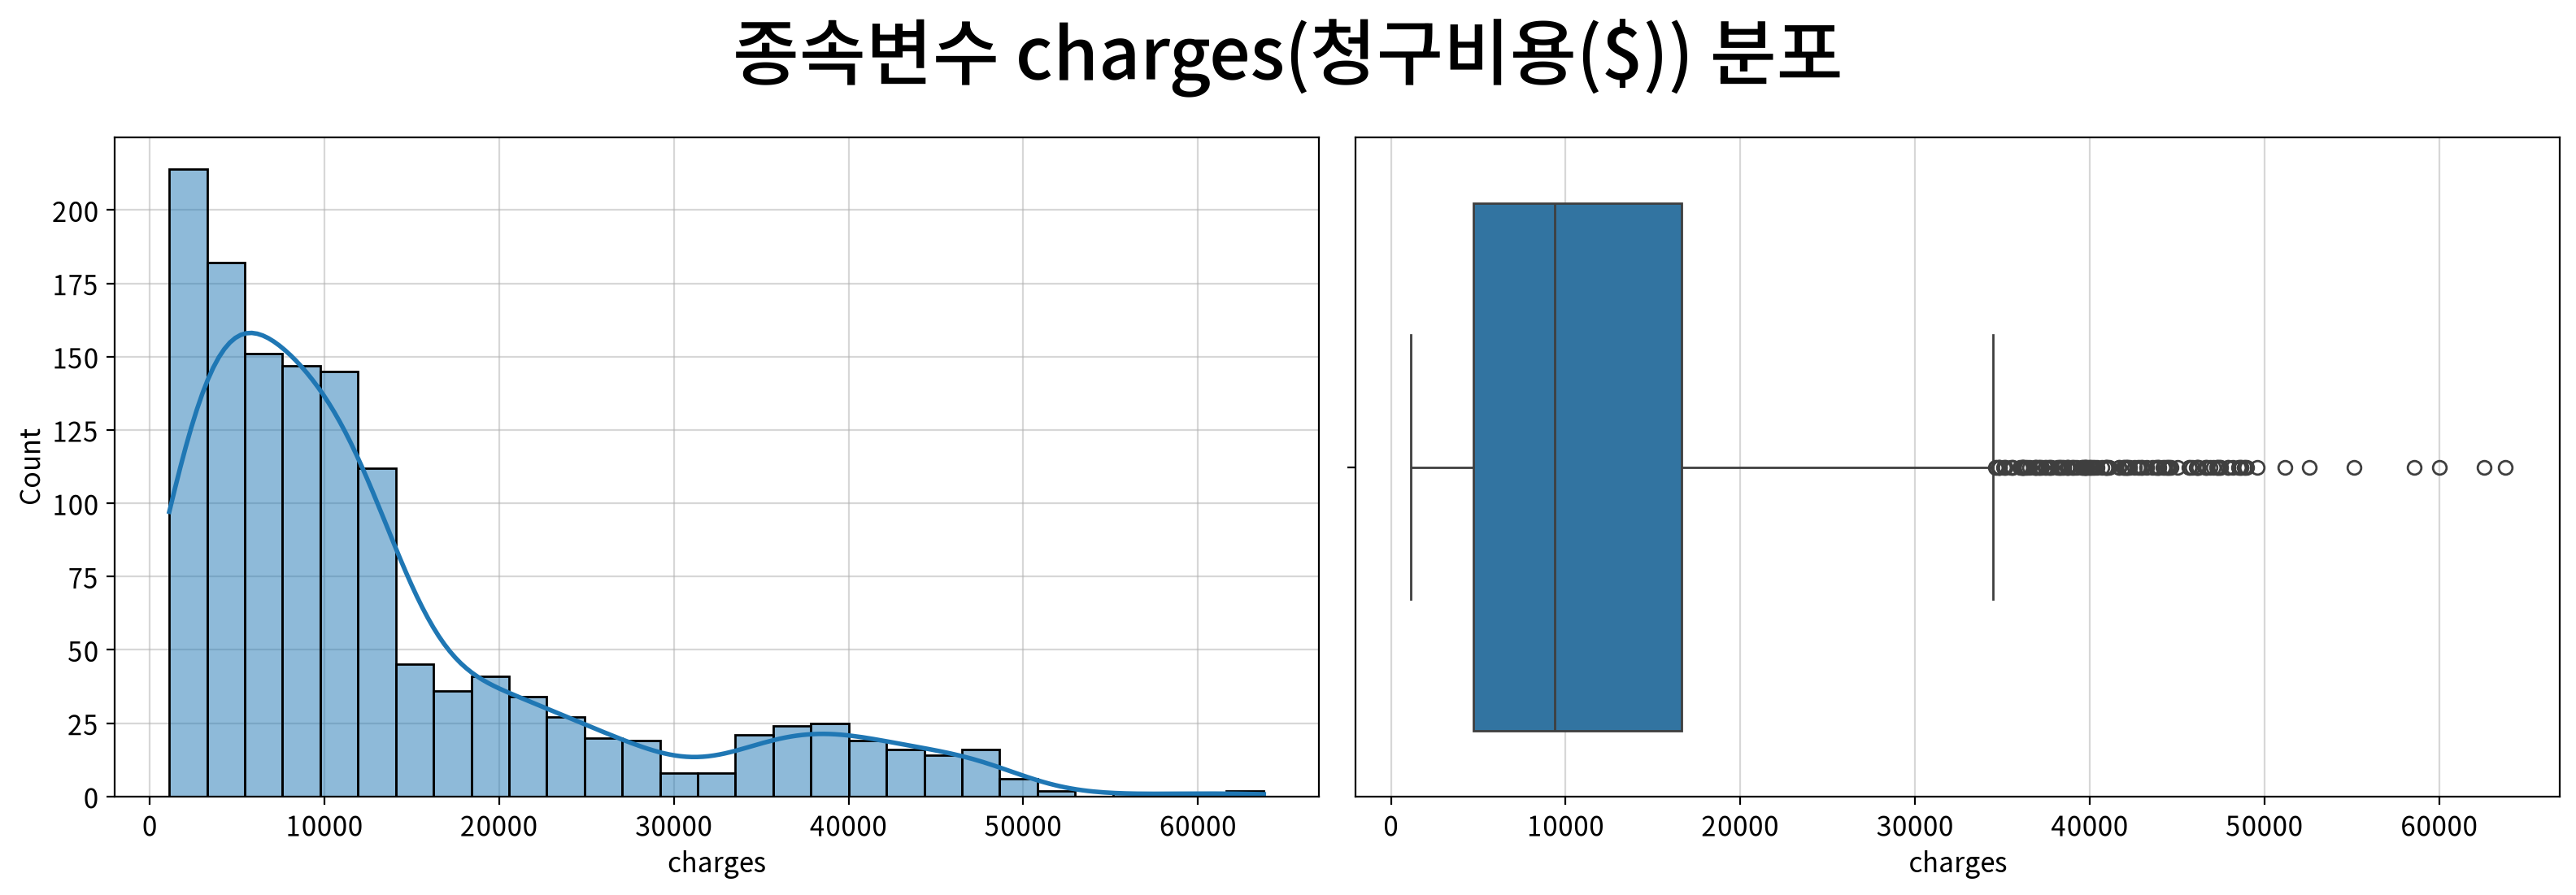

In [85]:
fig, ax = my_plot.init(rows=1, cols=2, width=800, height=560, title=f"종속변수 {target}({column_means[target]}) 분포")
my_plot.histplot(data=df, x=target, kde=True, ax=ax[0])
my_plot.boxplot(data=df, x=target, ax=ax[1])
my_plot.show()

### (2) 연속형 독립변수 분포

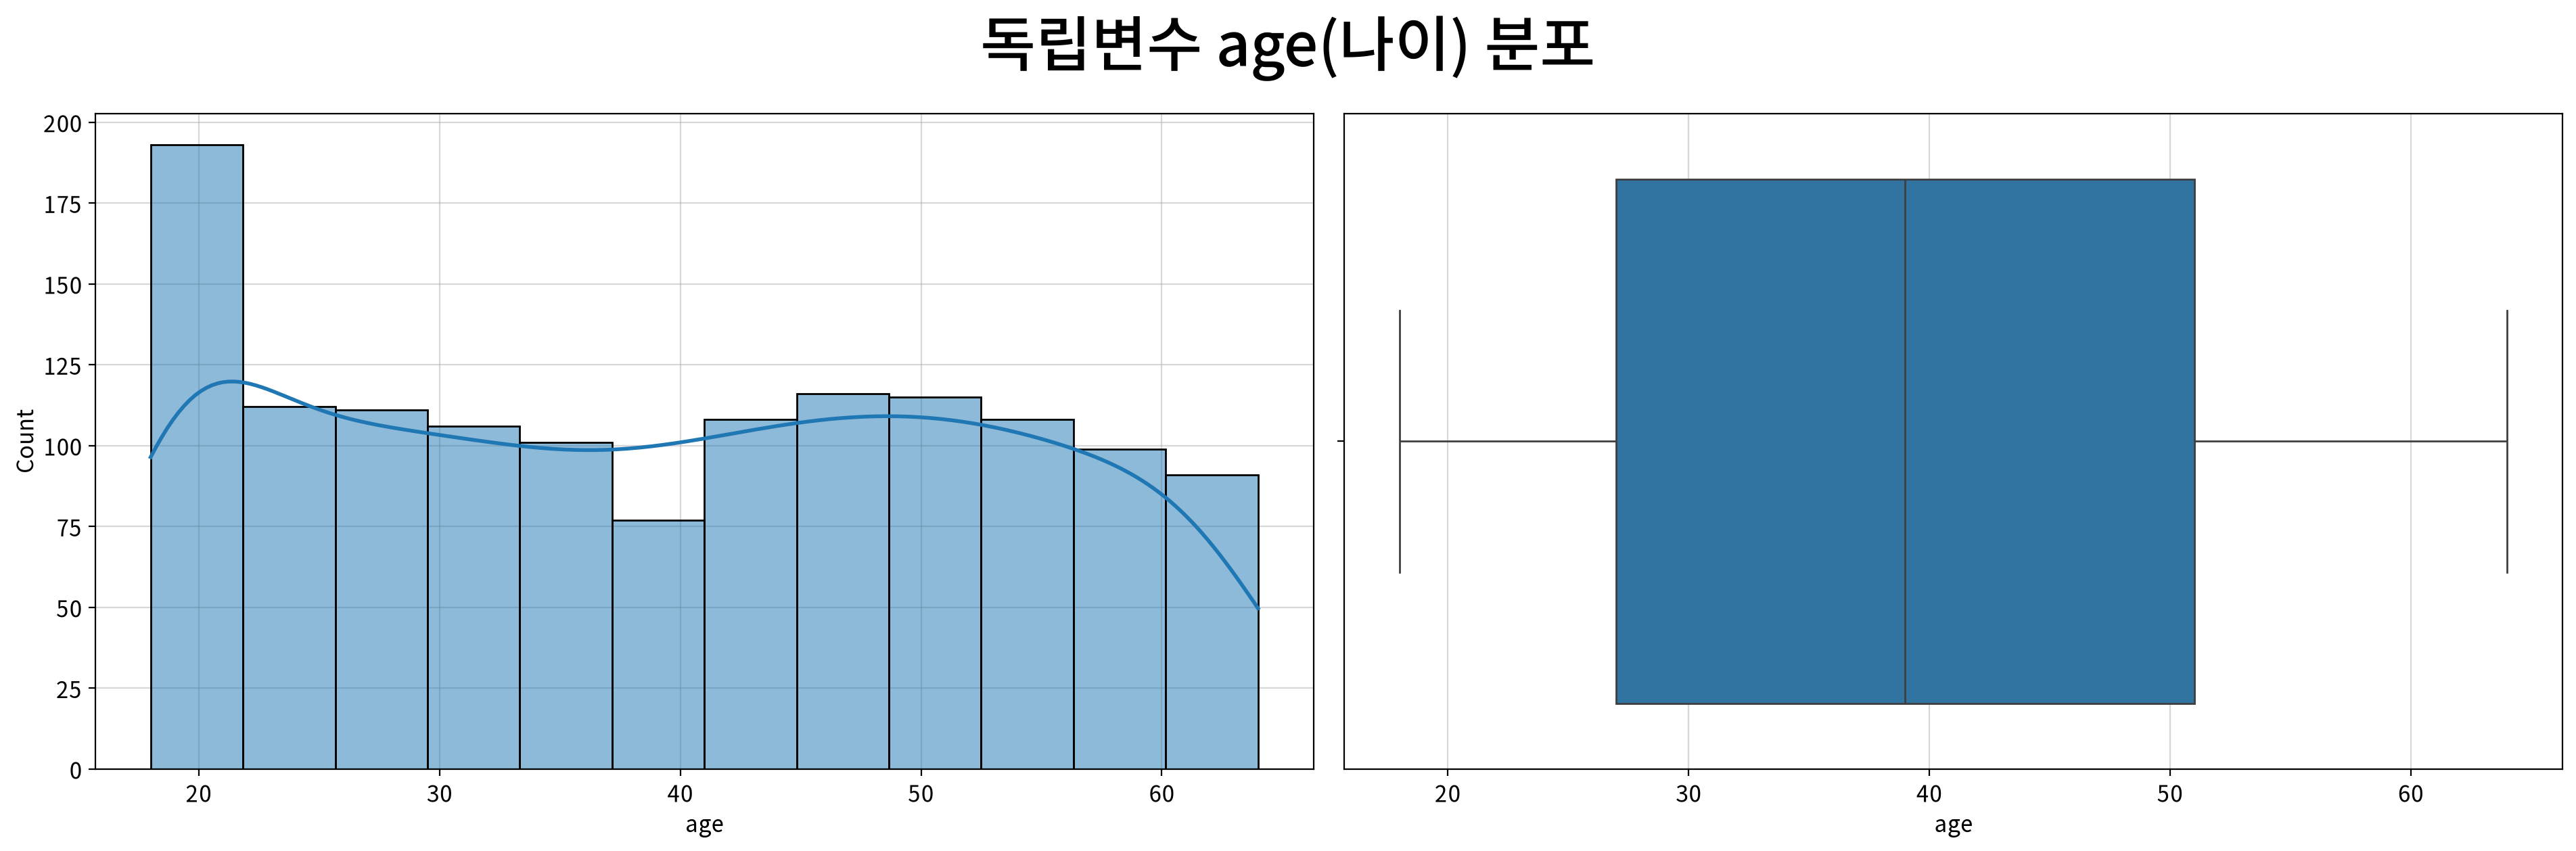

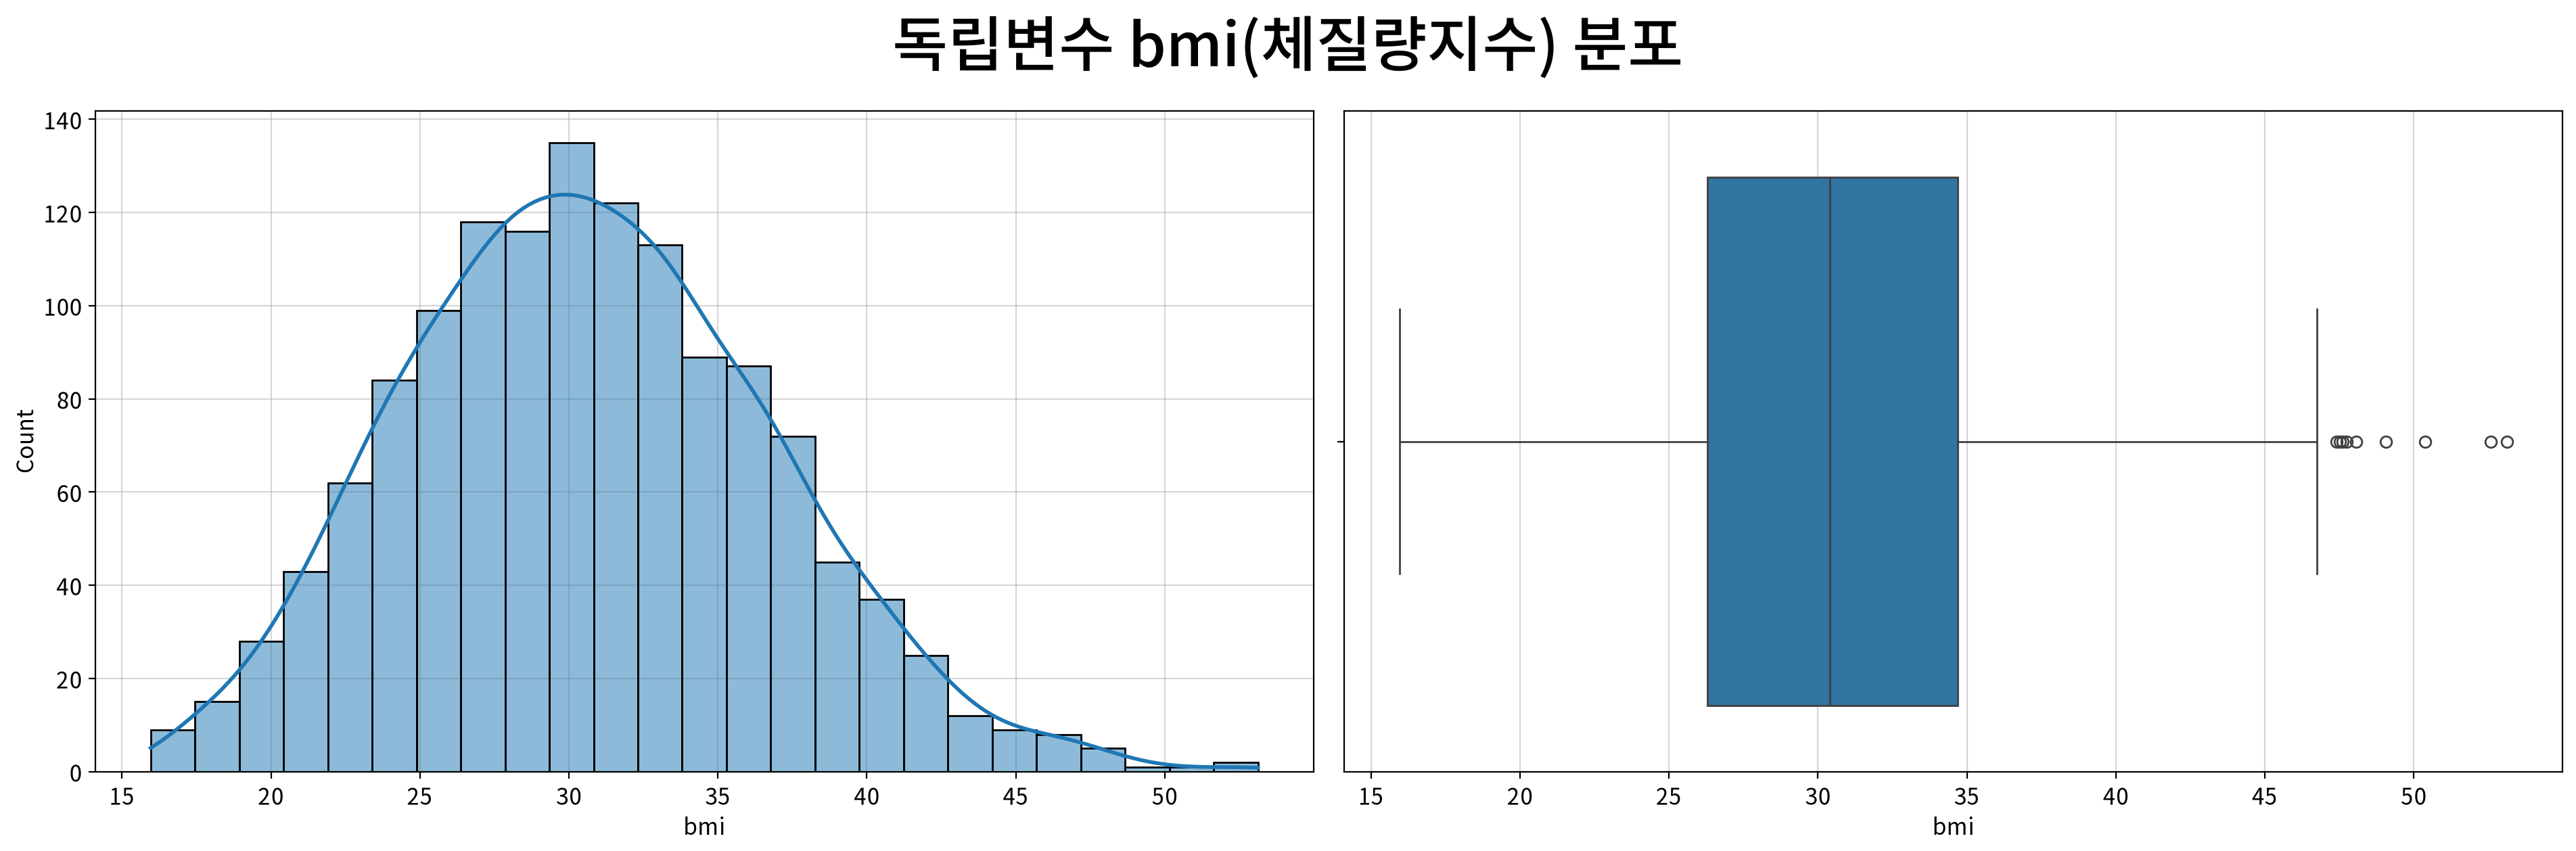

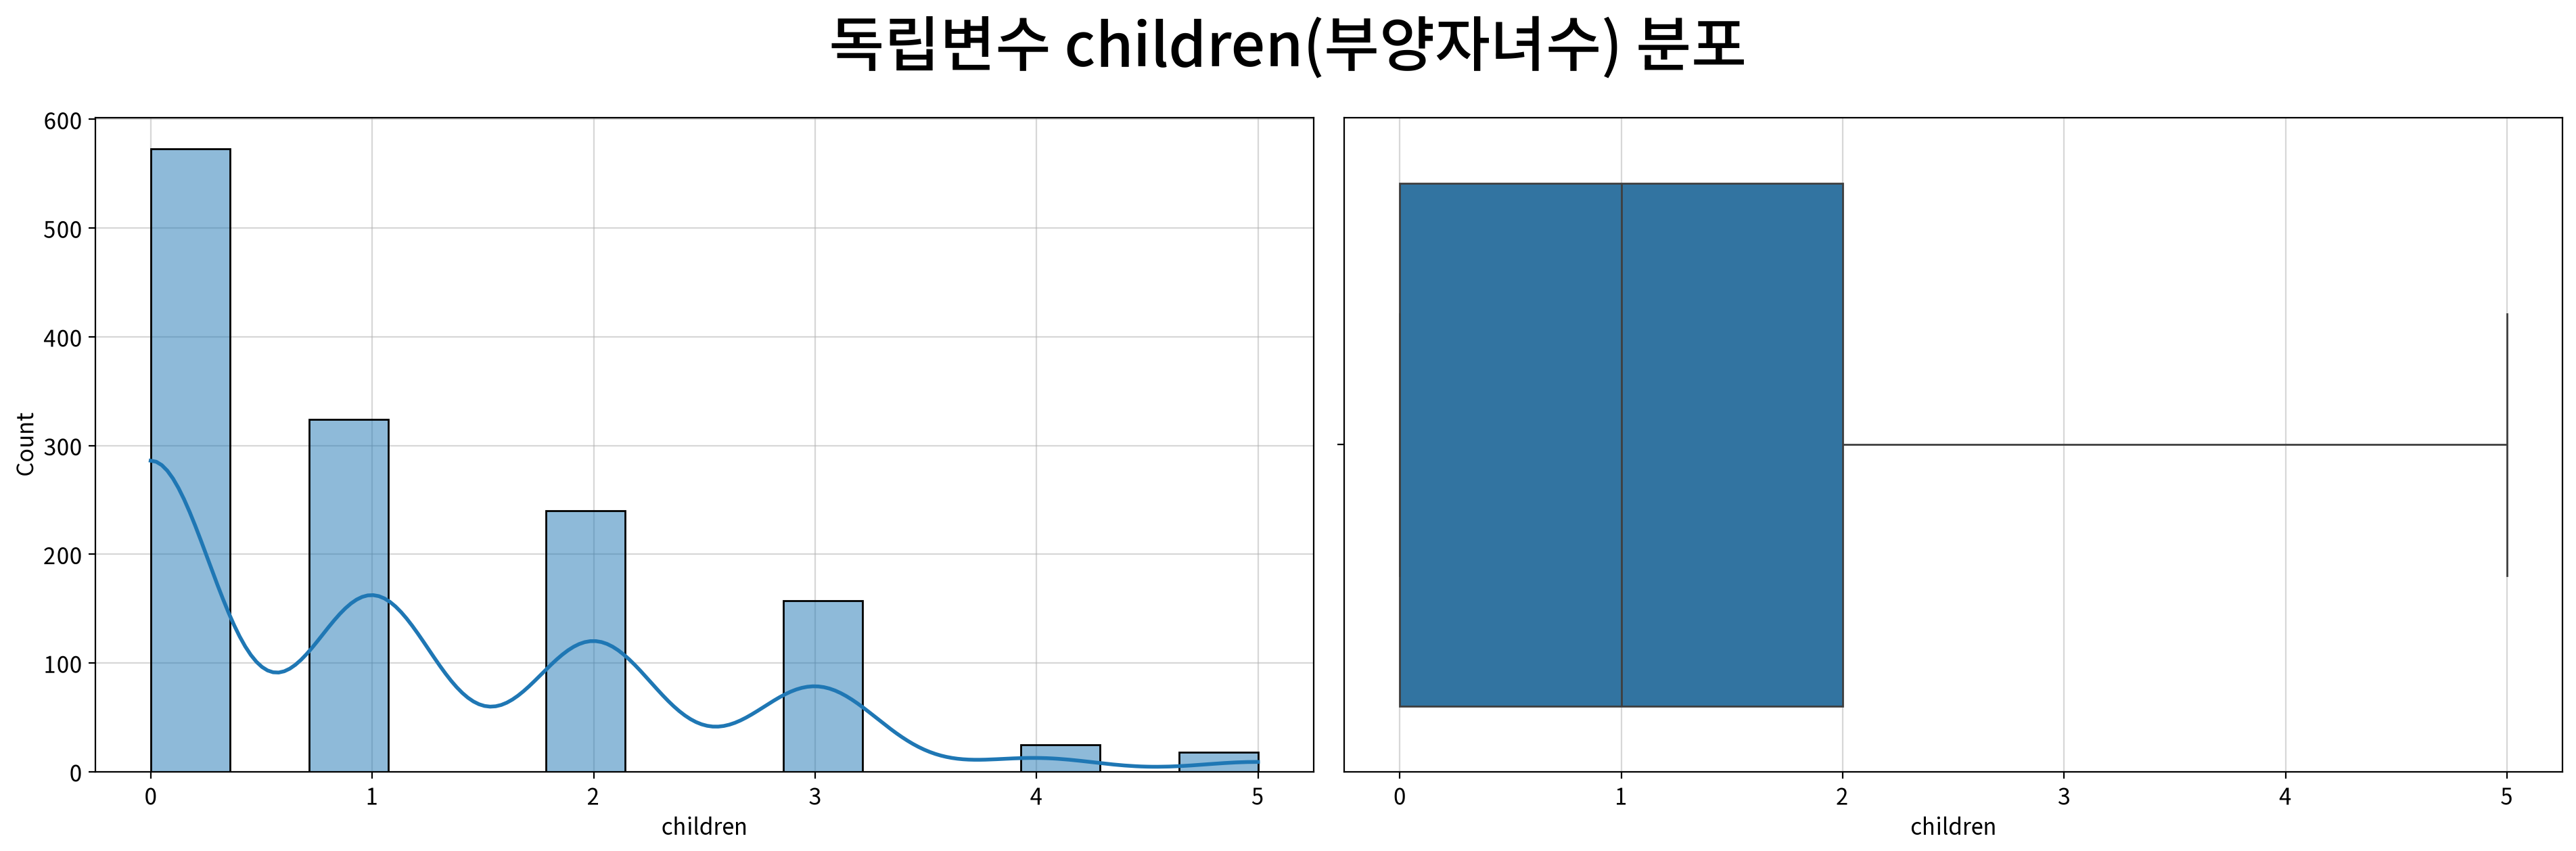

In [86]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                           title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

### (3) 명목형 독립변수 분포

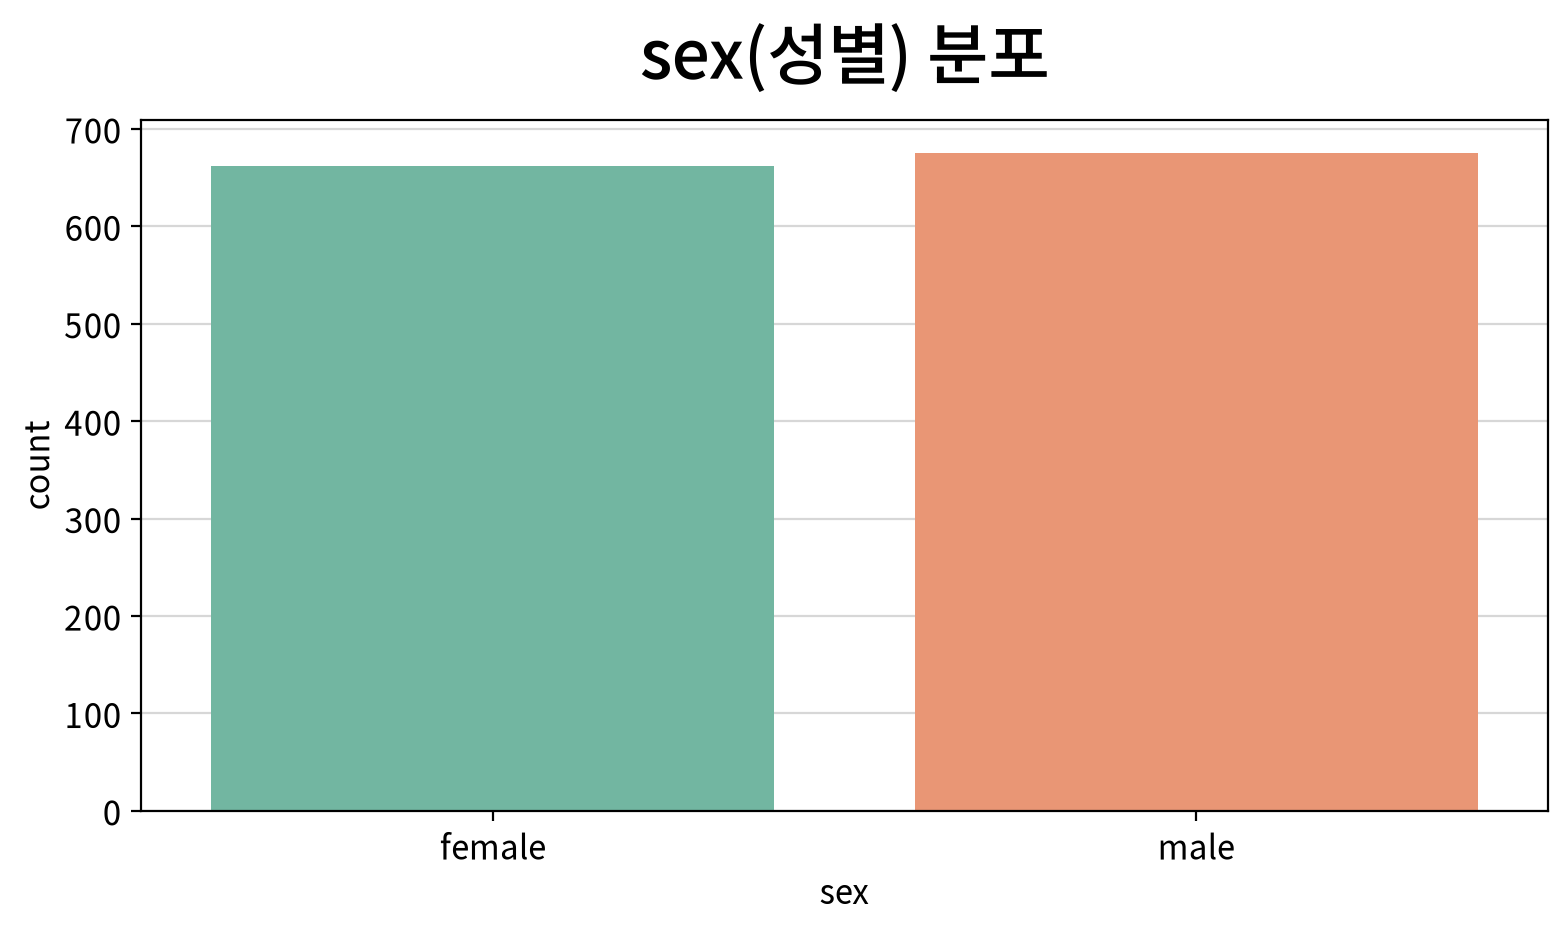

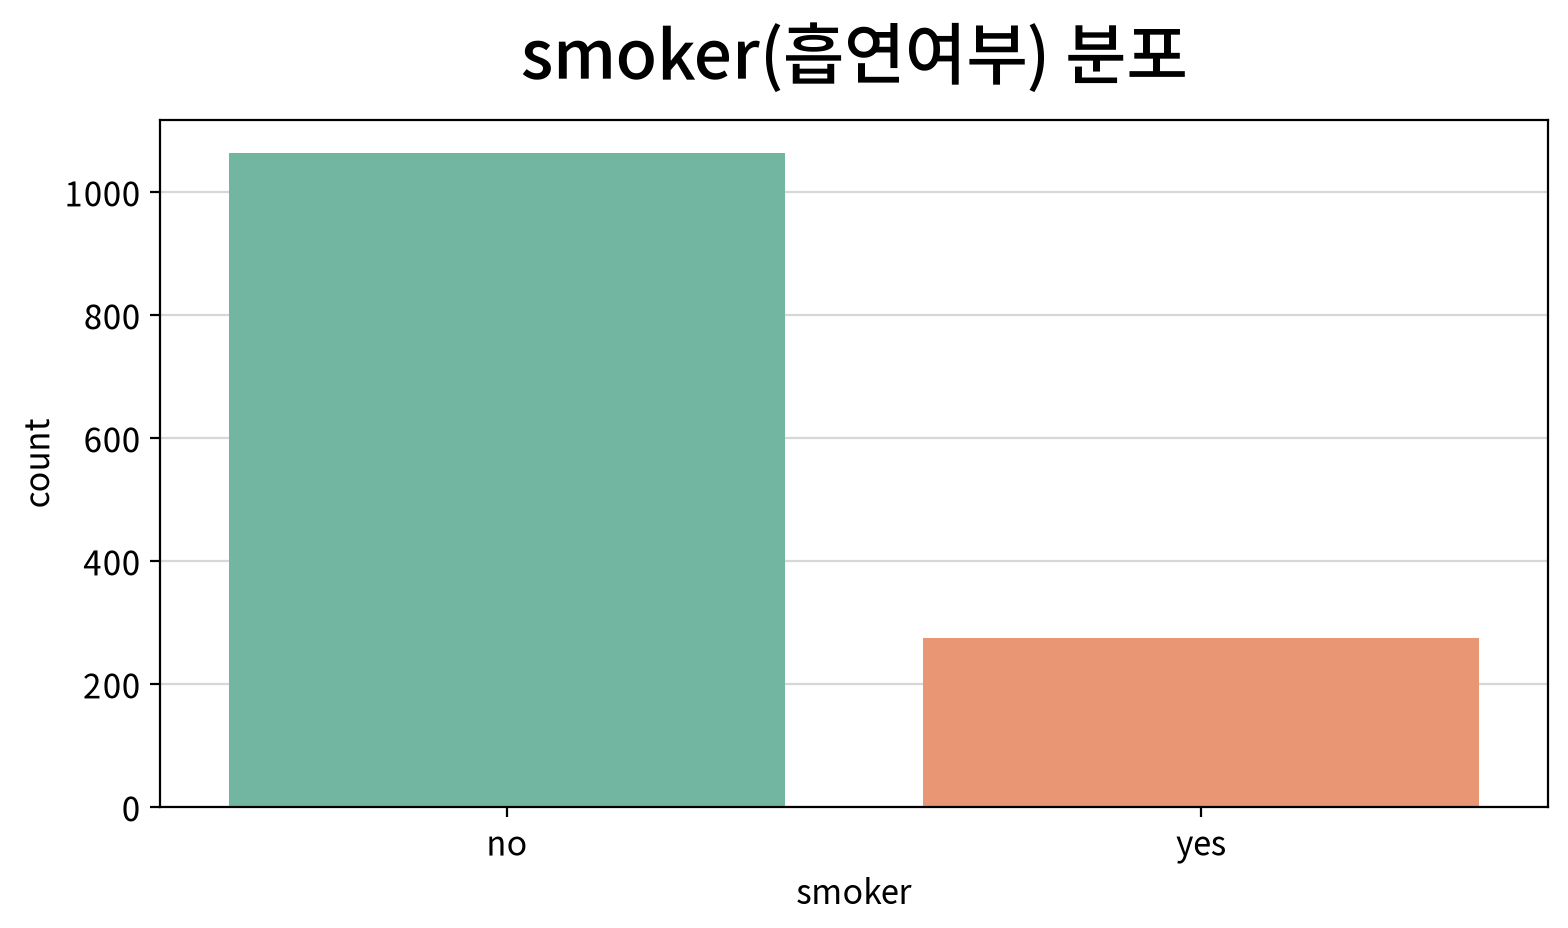

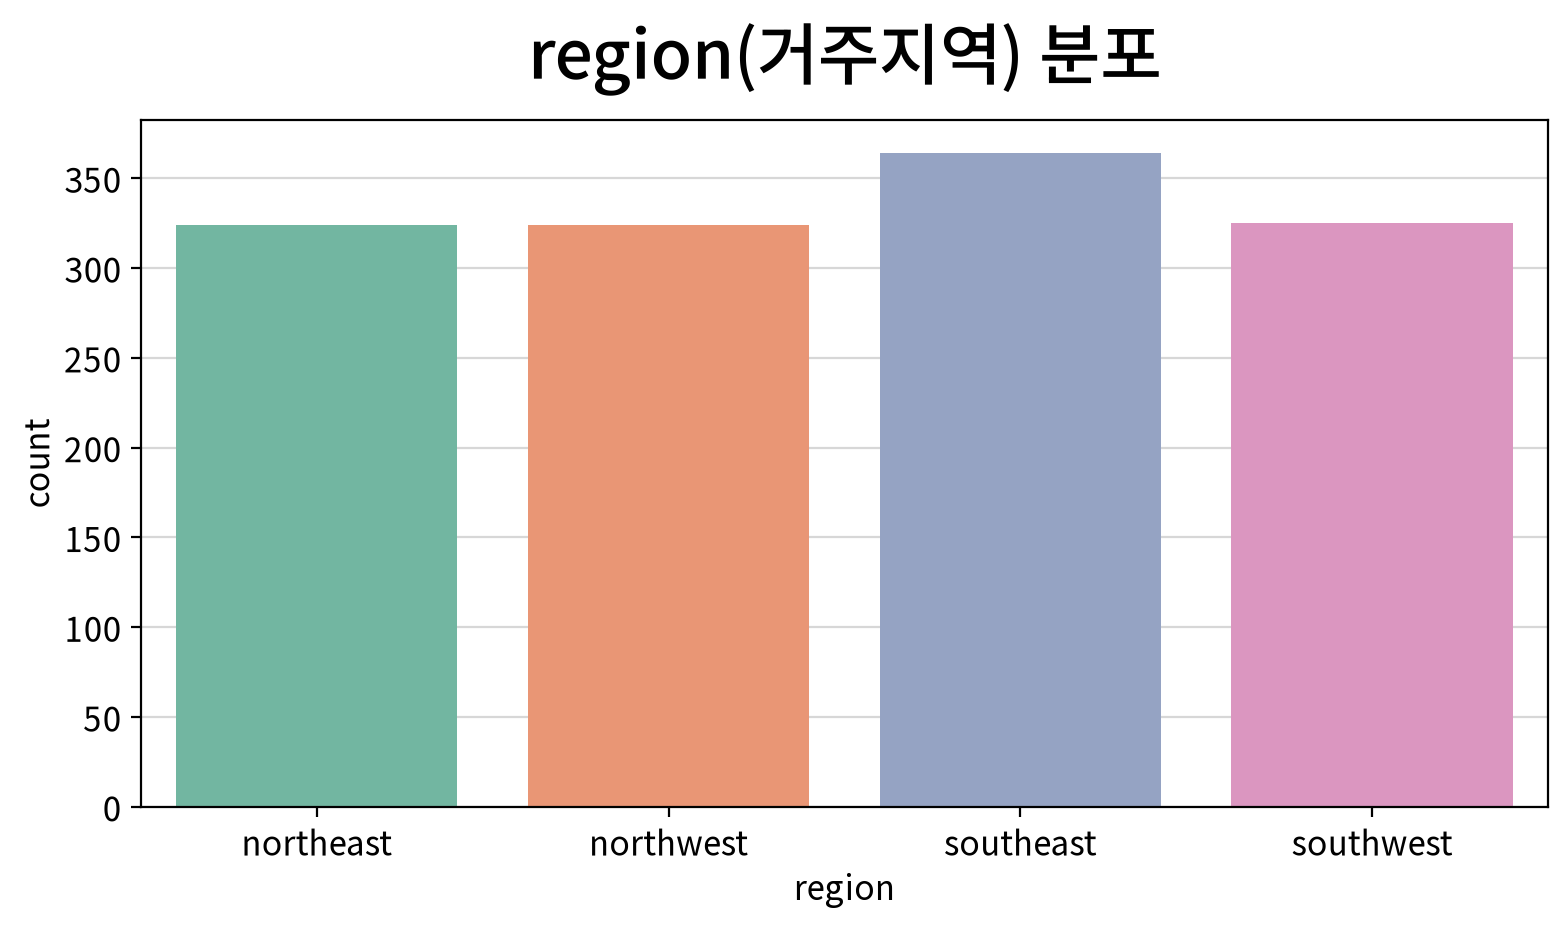

In [87]:
for n in nominal_cols:
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", width=800, height=480,
                      title=f"{n}({column_means[n]}) 분포")

> 💡 **인사이트 — 단변량**
>
> - `charges`는 강한 우편향(왜도 1.52)이고, 3~4만 달러 구간에 **두 번째 봉우리**가 있다. 하나의 분포가 아니라 **서로 다른 집단이 섞여 있다**는 신호다.
> - 그래프와 기술통계를 함께 보면, 모델 투입 전에 처리를 검토할 변수는 다음과 같다.
>
> | 변수 | 그래프 모양 | 이상치 비율 | 처리 방향 |
> |---|---|---|---|
> | `charges` | 1만 달러 이하에 몰린 우편향 + 3~4만 구간의 두 번째 봉우리 (왜도 1.52) | 10.4% (상단) | **log** |
> | `age` | 18~64세에 거의 균등하게 퍼지고, 18~19세에만 몰림 (왜도 0.06, 첨도 −1.24) | 0% | 그대로 (변환 불필요) |
> | `bmi` | 정규분포에 가까운 종 모양 (왜도 0.28) | 0.7% (상단) | 그대로 (변환 불필요) |
> | `children` | 0명이 가장 많고 갈수록 줄어드는 **이산형** 분포 (0~5명, 왜도 0.94) | 0% | **log1p** (0 포함) — 값이 6가지뿐인 이산형이라 변환 효과는 PART 3에서 검증 |
>
> - `charges`의 상단 이상치 139건(10.4%)은 입력 오류가 아니라 **고비용 집단**일 가능성이 크다. 로그변환이 이 구조를 해결하는지는 PART 3의 `1_로그변환` 체크포인트로 검증한다.
> - `bmi`는 평균 30.7로, **가입자 절반 이상이 비만 기준(30)을 넘는다.**
> - 명목형 중 `smoker`는 흡연자가 274명(20.5%)으로 **소수 집단**이다. `sex`(662 : 675)와 `region`(324~364명)은 고르게 분포한다.

## 2-2. 이변량 분석 — 각 독립변수가 청구비용을 설명하는가?

### (1) 연속형 × 연속형 : 상관분석

- 정규성 · 선형성 · 영향점을 점검해 **Pearson / Spearman을 자동 선택**한다.
- 채택 기준 : **유의(p < 0.05) + 상관강도 Moderate 이상(|ρ| ≥ 0.3)**

#### ▶︎ age(나이) → charges

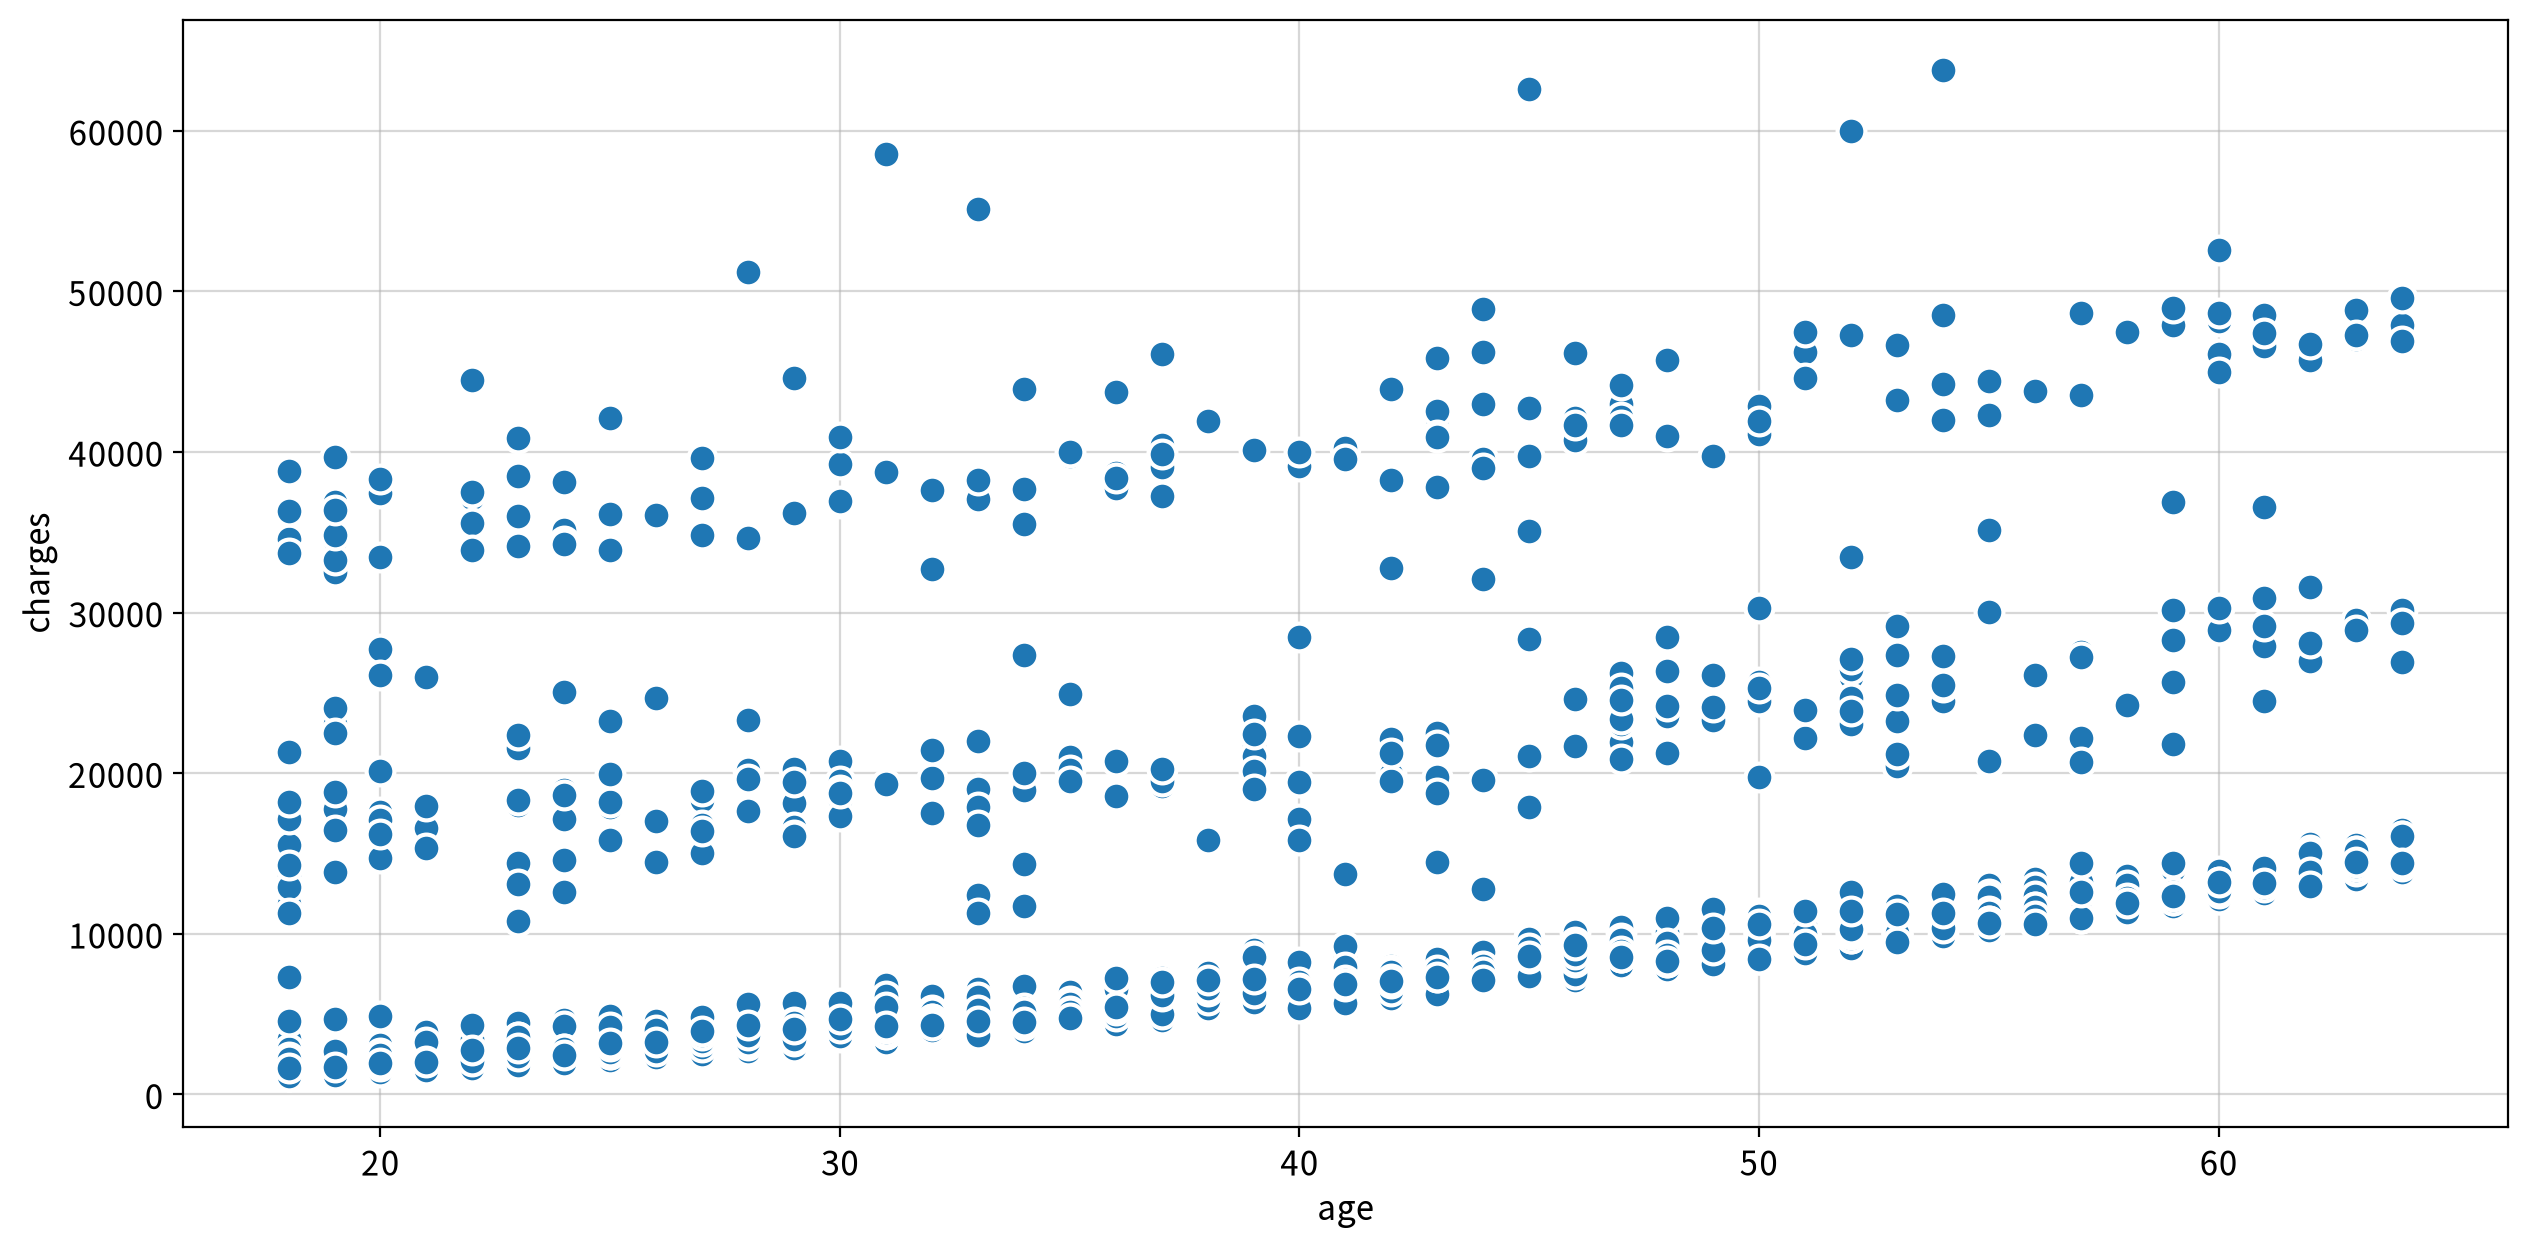

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
age,charges,Spearman,0.533,0.000,Moderate,True,False,False,True,True,True


#### ▶︎ bmi(체질량지수) → charges

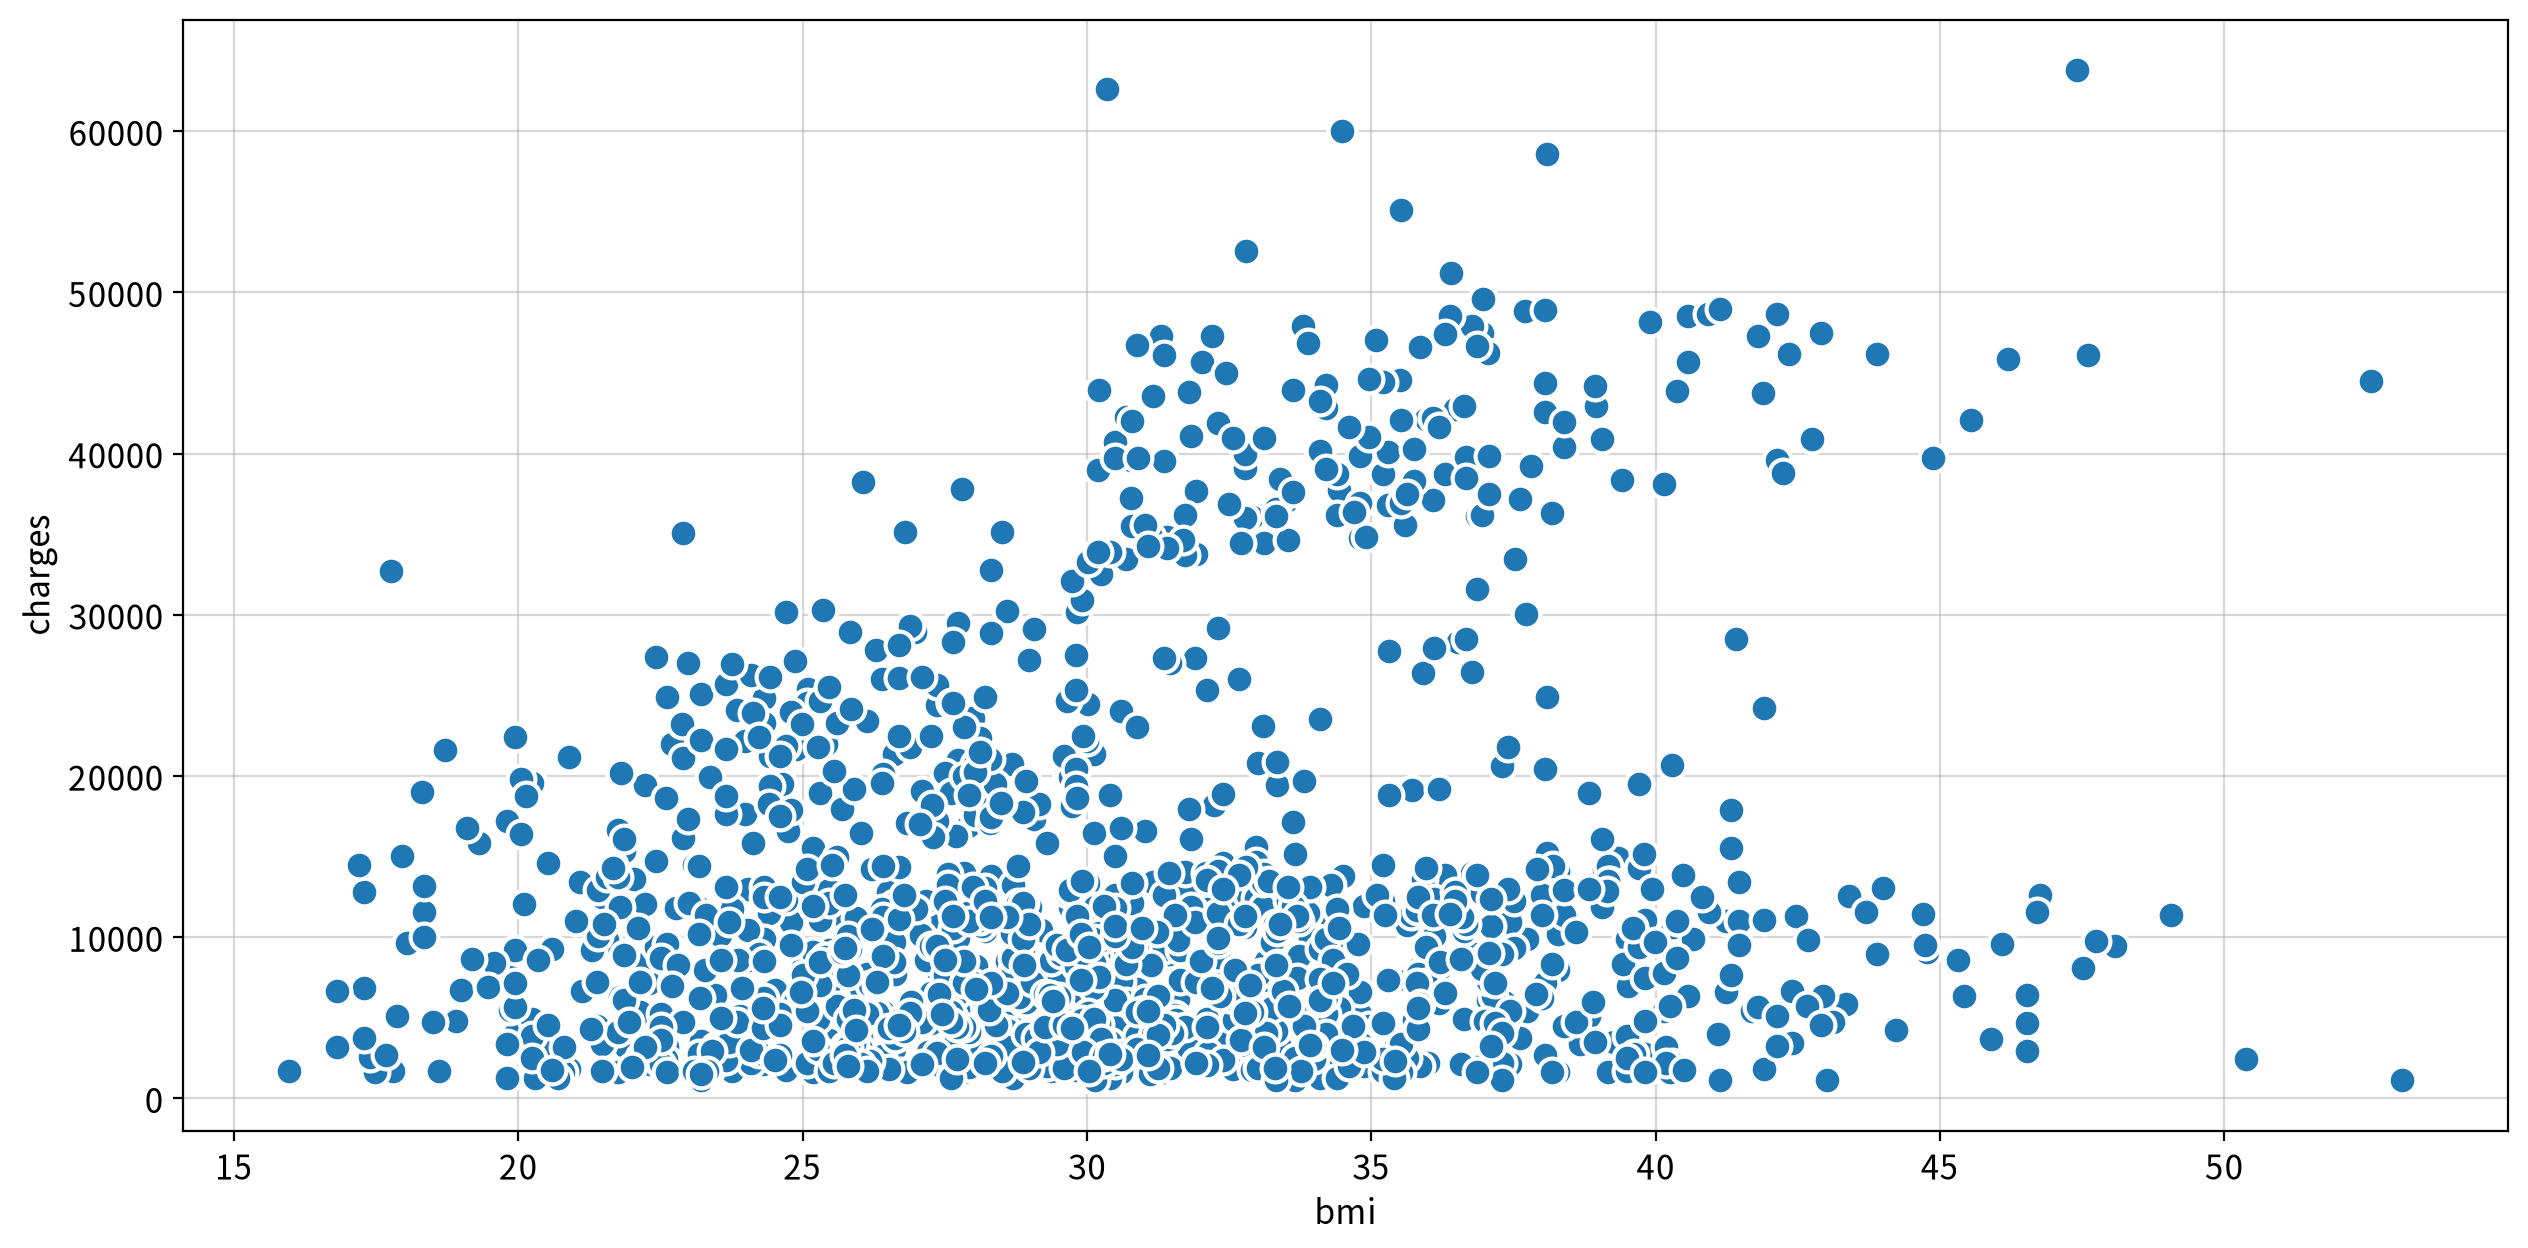

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
bmi,charges,Spearman,0.120,0.000,Weak,True,False,False,True,True,True


#### ▶︎ children(부양자녀수) → charges

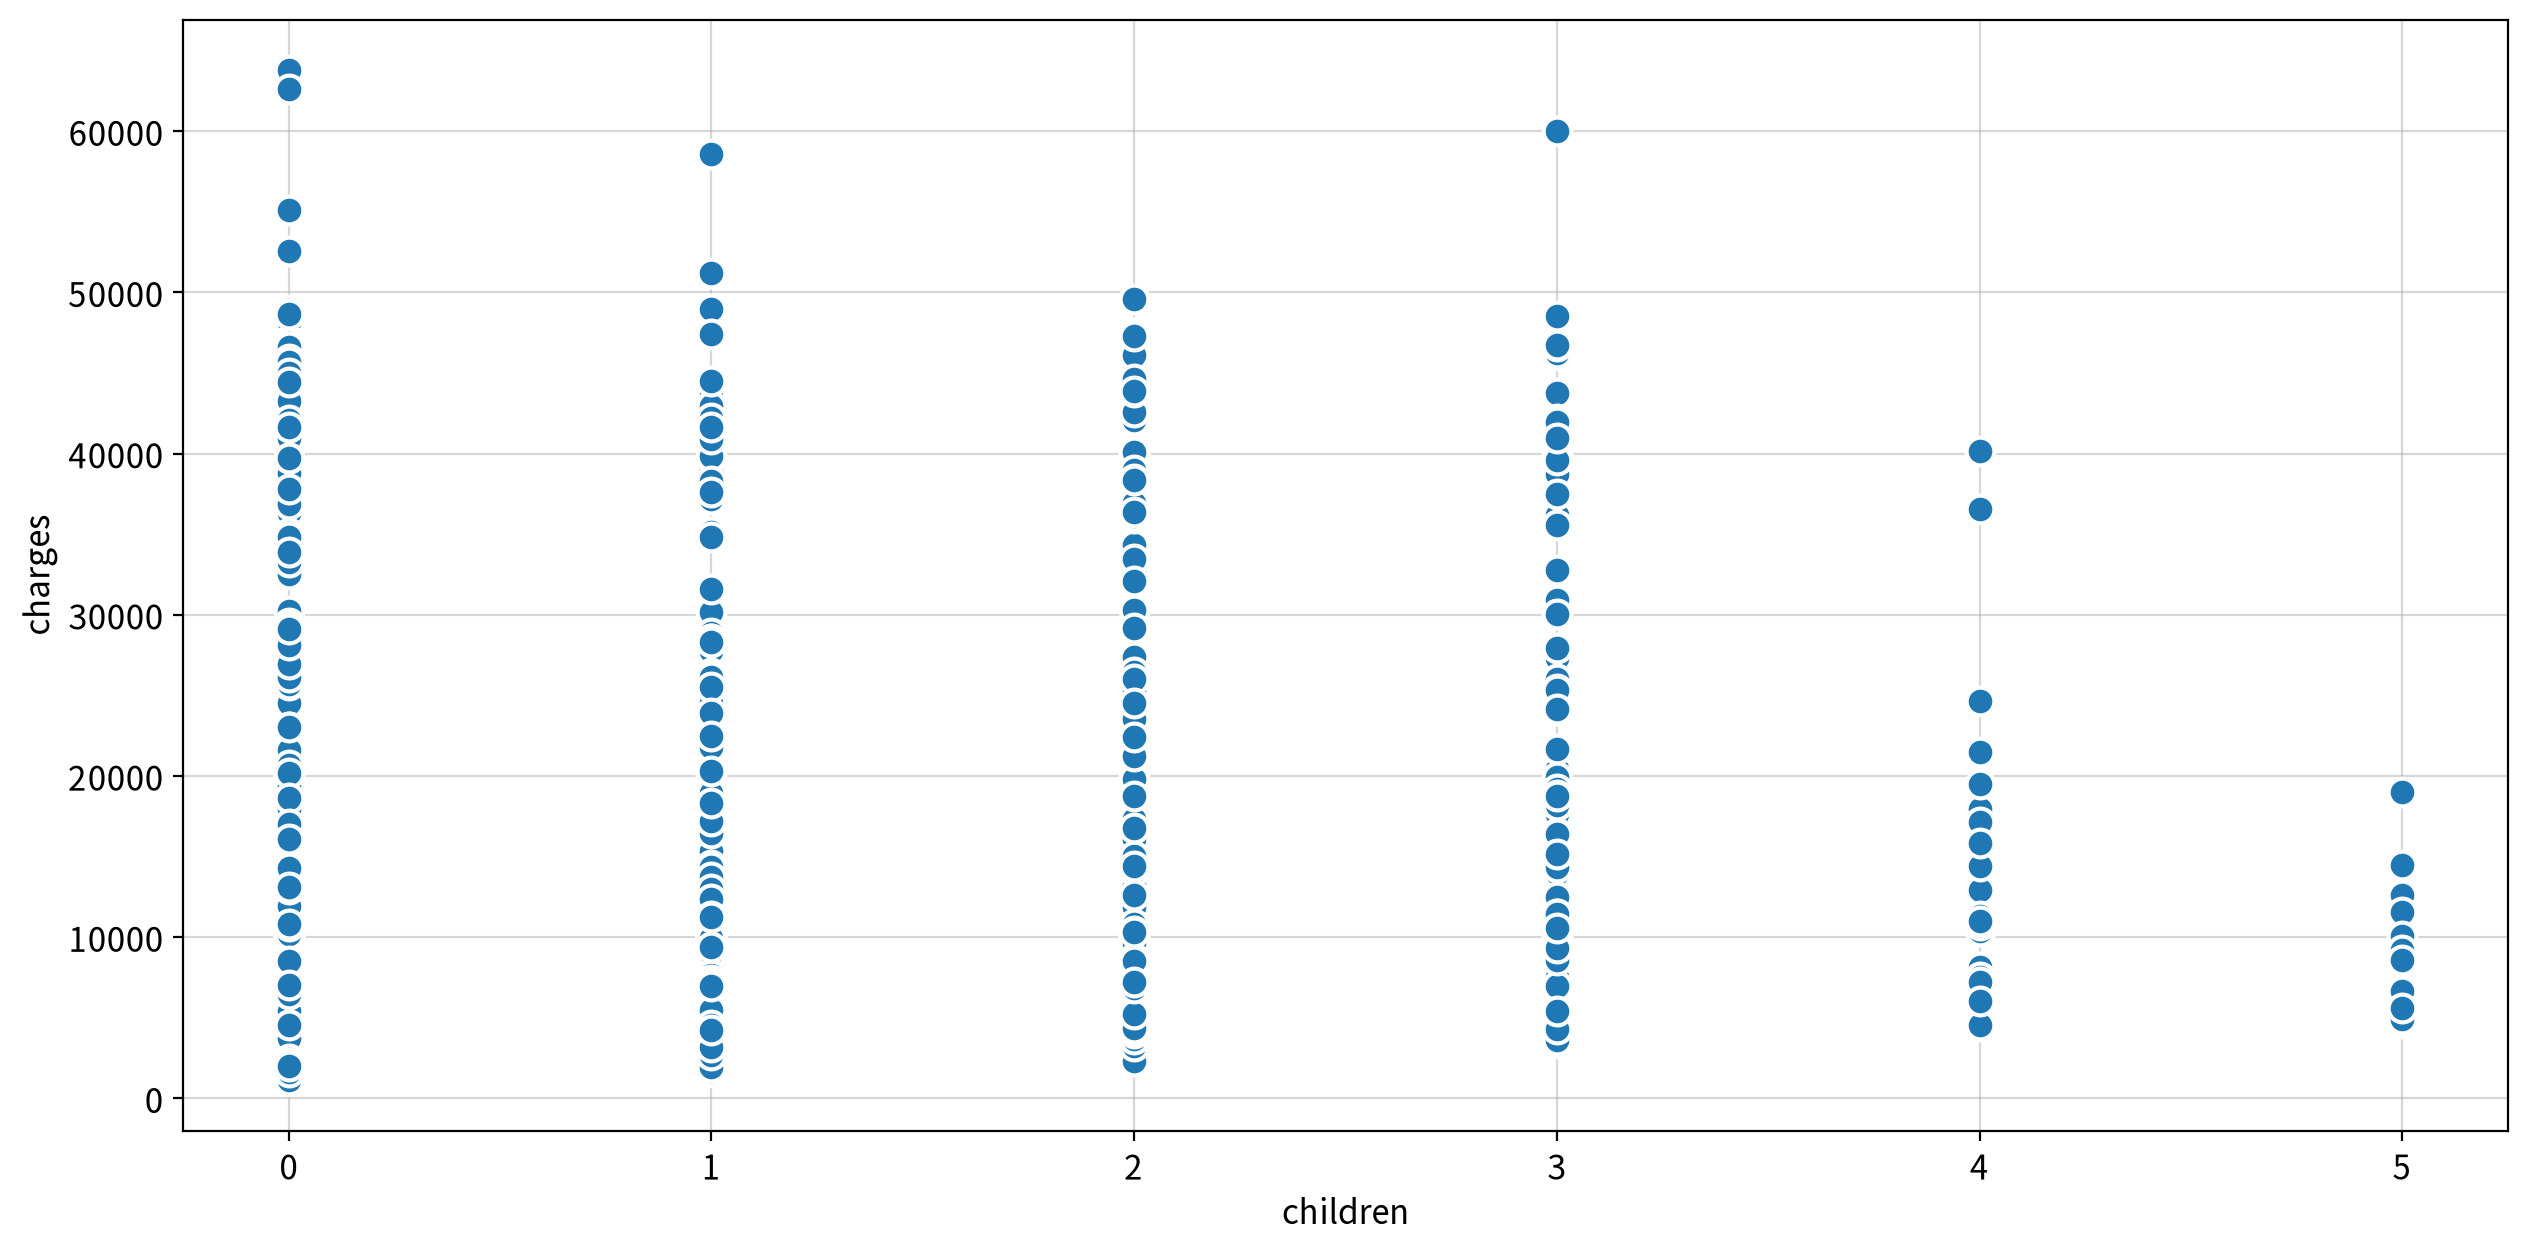

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
children,charges,Spearman,0.132,0.000,Weak,True,False,False,False,False,True


In [ ]:
for f in continuous_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}")) # h4
    
    # my_stats는 시각화까지 일괄처리 한다.
    display(my_stats.correlation(data=df, x=f, y=target)) 

> 💡 **인사이트 — 이변량 (연속형 × charges)**
>
> - ⚠️ 판정은 **"개별 독립변수 ↔ 종속변수(`charges`) 단독 관계"만 기준**으로 한다. 변수 간 중복(공선성)은 여기서 고려하지 않으며, 다음 다변량 분석과 PART 3의 VIF 단계에서 점검한다. 변수별 최종 판정은 아래 (4) 변수 채택 결과 표에 정리했다.
>
> - **3개 중 1개 채택, 2개(`bmi` · `children`) 보류.** 가장 강한 신호는 **`age`(ρ = +0.533)** 다. 나이가 많을수록 청구비용이 높다.
> - `bmi`(ρ = +0.120)와 `children`(ρ = +0.132)은 유의하지만 **관계가 약하다.** 단독으로는 청구비용을 거의 설명하지 못한다.
> - `charges`와 독립변수 모두 정규성이 깨져 있어 **모든 변수에서 Spearman이 선택됐다.** 
> - **선형성은 `age` · `bmi`에서 확인됐고, `children`만 곡선 관계**다. `children`은 값이 6가지뿐인 이산형이라 직선으로 표현하기 어렵다.
> - `age` · `bmi`는 **영향점(influential outlier)** 이 감지됐다. 산점도에서 같은 나이 · 같은 BMI인데도 청구비용이 크게 높은 점들이 따로 떨어져 있다. 단변량에서 본 **고비용 집단**이 여기서도 드러나는 것으로, 이 집단의 정체는 다변량 분석에서 확인한다.
> - 보류한 `bmi` · `children`은 버리지 않고 모델에 넣어, 회귀계수의 유의성으로 최종 판정한다. 특히 `bmi`는 단독 관계가 약해도 **다른 변수와 결합할 때 효과가 드러날 수 있어** 다변량 분석에서 다시 살펴본다.

### (2) 명목형(2집단) × 연속형 : 독립표본 검정

#### ▶︎ sex(성별) → charges

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

female vs. male: Mann-Whitney-Wilcoxon test two-sided, P_val:6.945e-01 U_stat=2.207e+05


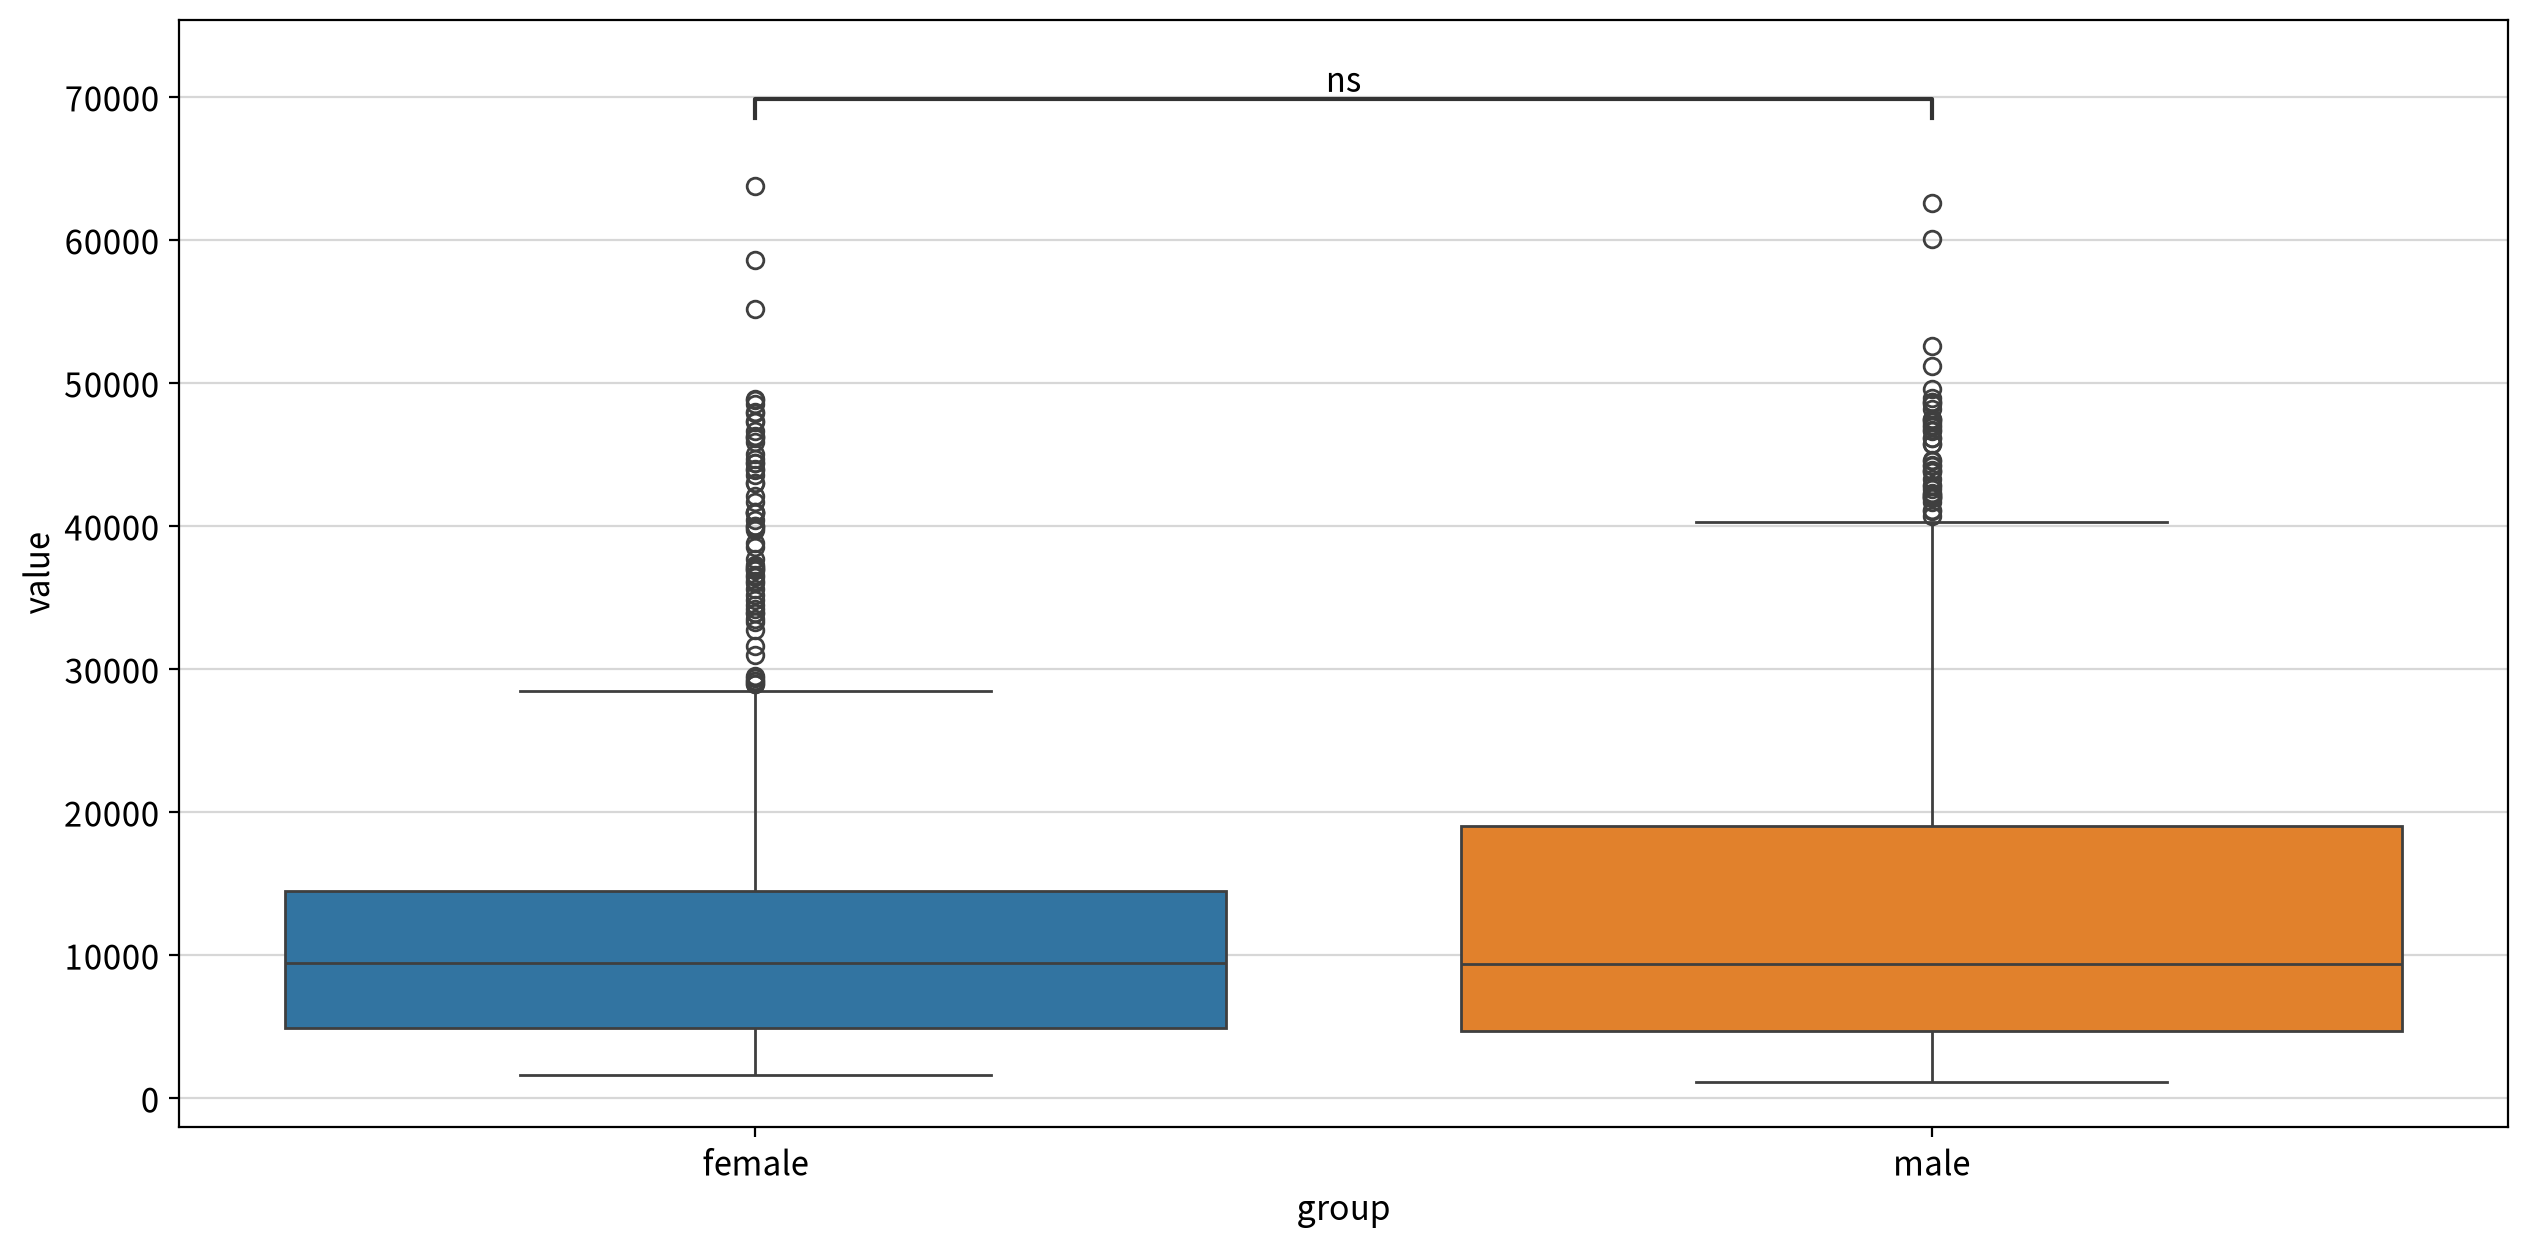

statistic  p-value  significant  \
test                alternative                                     
Mann-Whitney U test two-sided   220,652.000    0.695        False   
                    less        220,652.000    0.347        False   
                    greater     220,652.000    0.653        False   

                                        result  
test                alternative                 
Mann-Whitney U test two-sided    female = male  
                    less         female ≥ male  
                    greater      female ≤ male

#### ▶︎ smoker(흡연여부) → charges

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

no vs. yes: Mann-Whitney-Wilcoxon test two-sided, P_val:0.000e+00 U_stat=7.403e+03


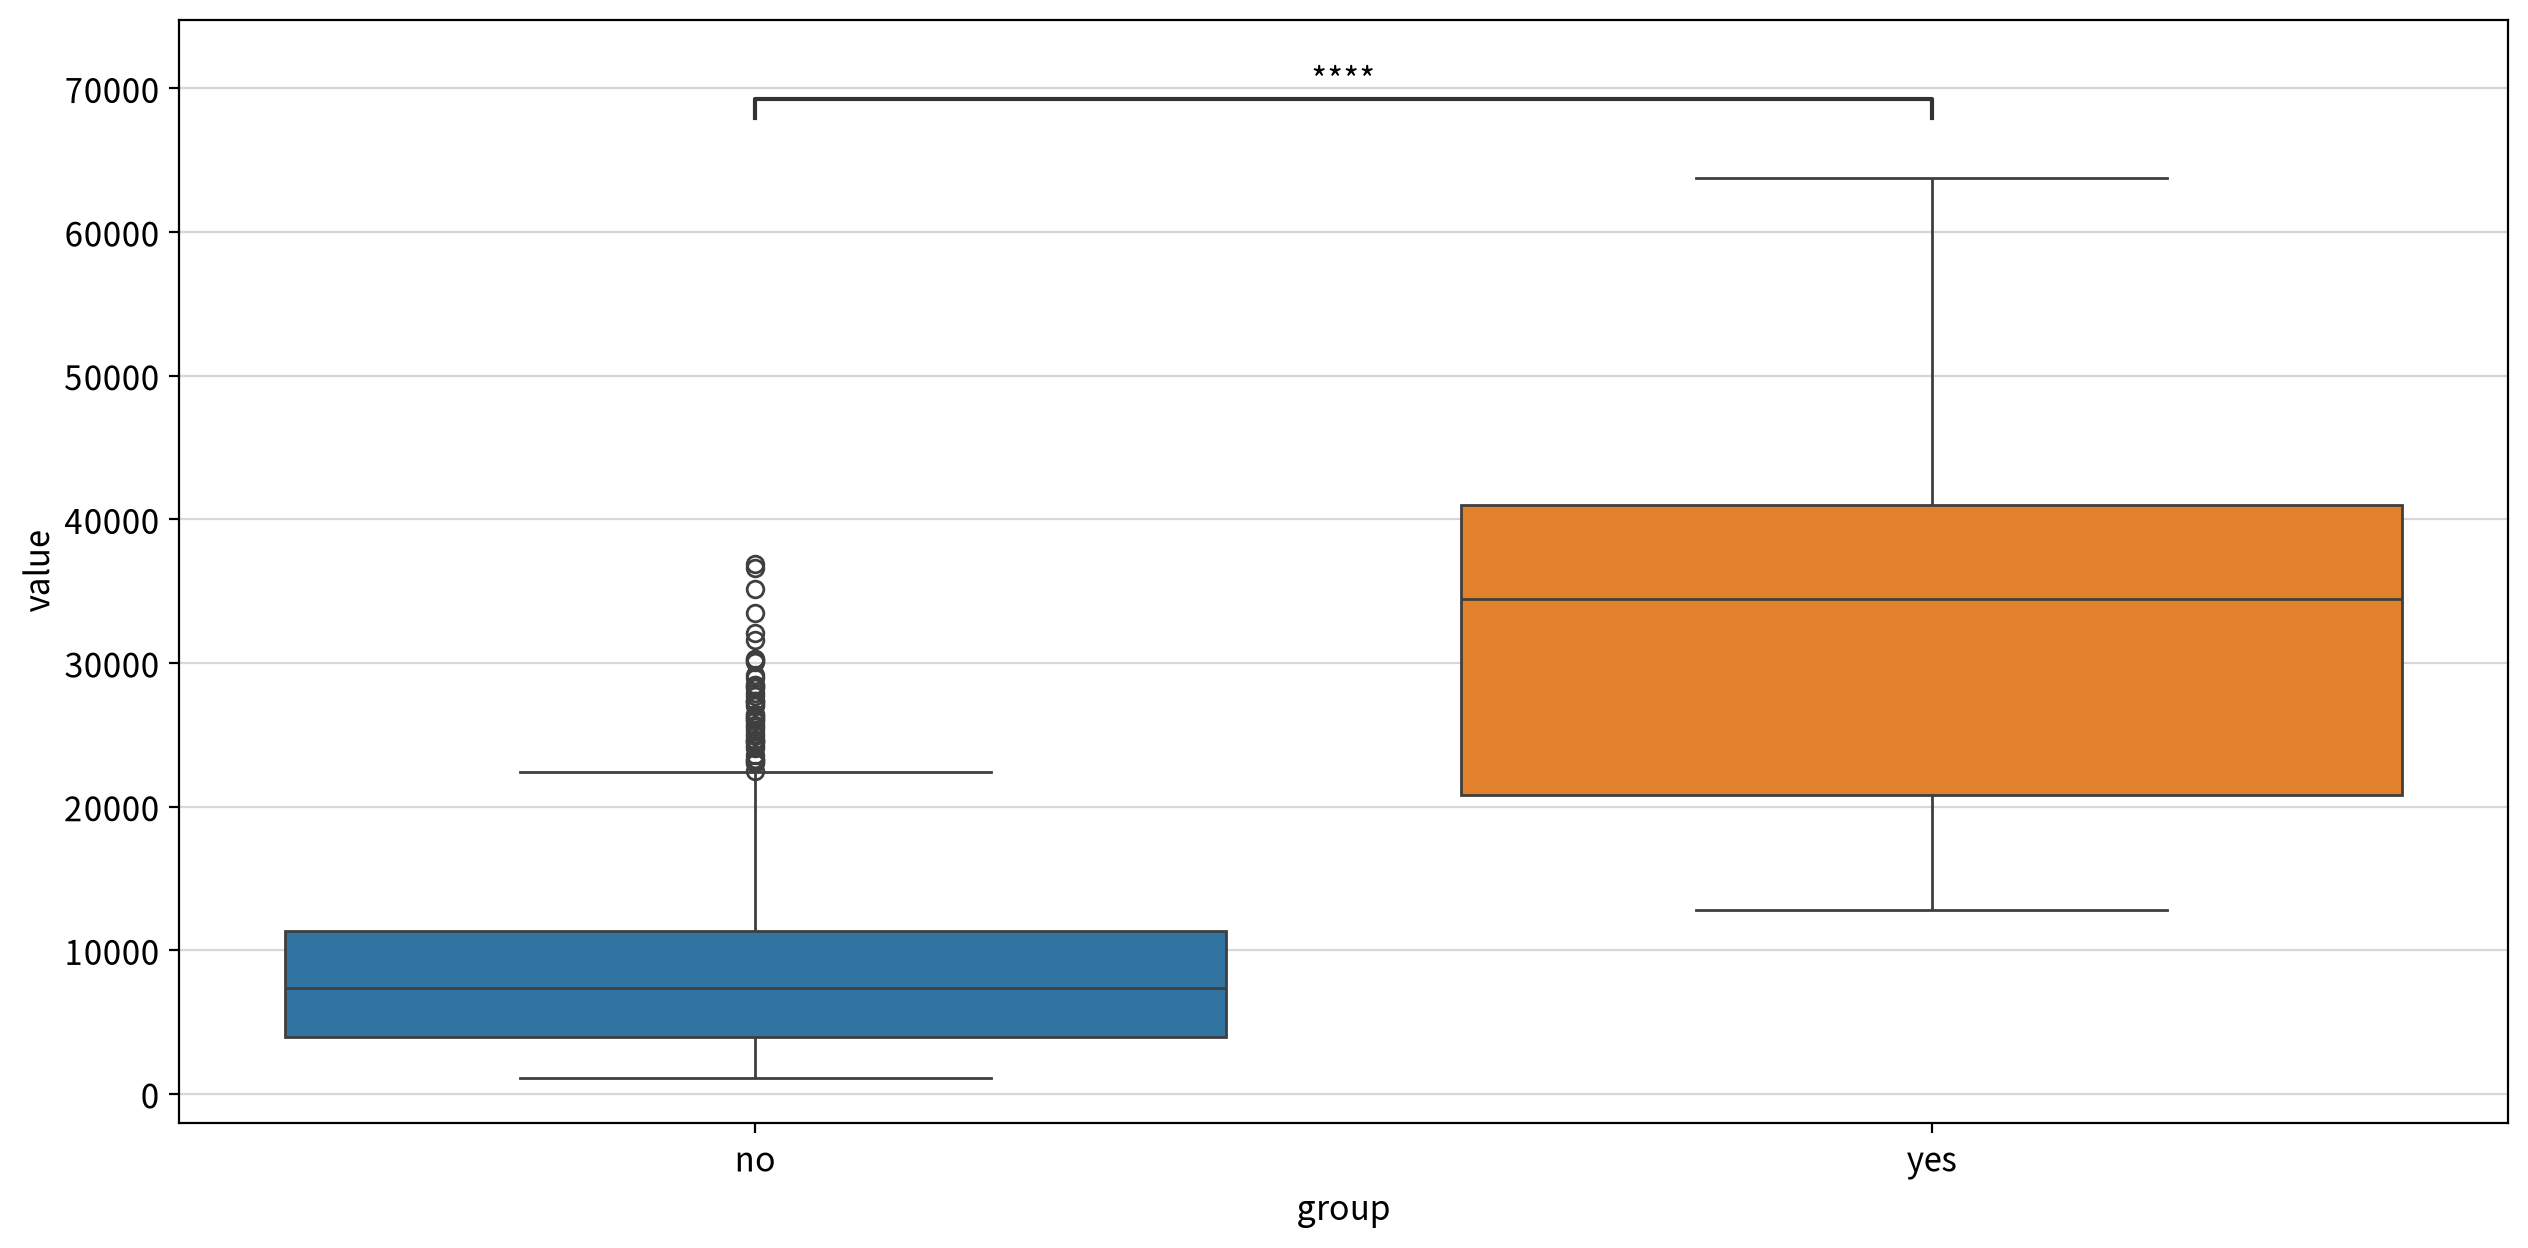

statistic  p-value  significant    result
test                alternative                                           
Mann-Whitney U test two-sided    7,403.000    0.000         True  no ≠ yes
                    less         7,403.000    0.000         True  no < yes
                    greater      7,403.000    1.000        False  no ≤ yes

In [89]:
for n in [c for c in nominal_cols if df[c].nunique() == 2]:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    # 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
    wide = my_prep.long2wide(df, hue=n, values=target)
    display(my_stats.test_independent(wide, group1=wide.columns[0], group2=wide.columns[1]))

> 💡 **인사이트 — 이변량 (sex · smoker × charges)**
>
> - `smoker`는 Mann-Whitney U에서 **흡연자 집단이 압도적으로 높았다**(양측 p < 0.001, 단측(no < yes) p < 0.001). 단변량에서 본 **고비용 집단**의 유력한 후보다.
> - `sex`는 **통계적으로 유의한 차이가 없었다**(양측 p = 0.695). 성별은 청구비용을 설명하지 못한다.

### (3) 명목형(3집단 이상) × 연속형 : 일원분산분석 + 사후검정

- `anova_oneway`는 등분산 여부에 따라 **ANOVA / Welch ANOVA**를 자동 선택한다.

#### ▶︎ region(거주지역) → charges

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,region,3,740.416,2.566,0.053,0.007,Negligible


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

northeast vs. northwest: Custom statistical test, P_val:6.962e-01
northwest vs. southeast: Custom statistical test, P_val:8.019e-02
southeast vs. southwest: Custom statistical test, P_val:6.826e-02
northeast vs. southeast: Custom statistical test, P_val:5.122e-01
northwest vs. southwest: Custom statistical test, P_val:9.994e-01
northeast vs. southwest: Custom statistical test, P_val:6.378e-01


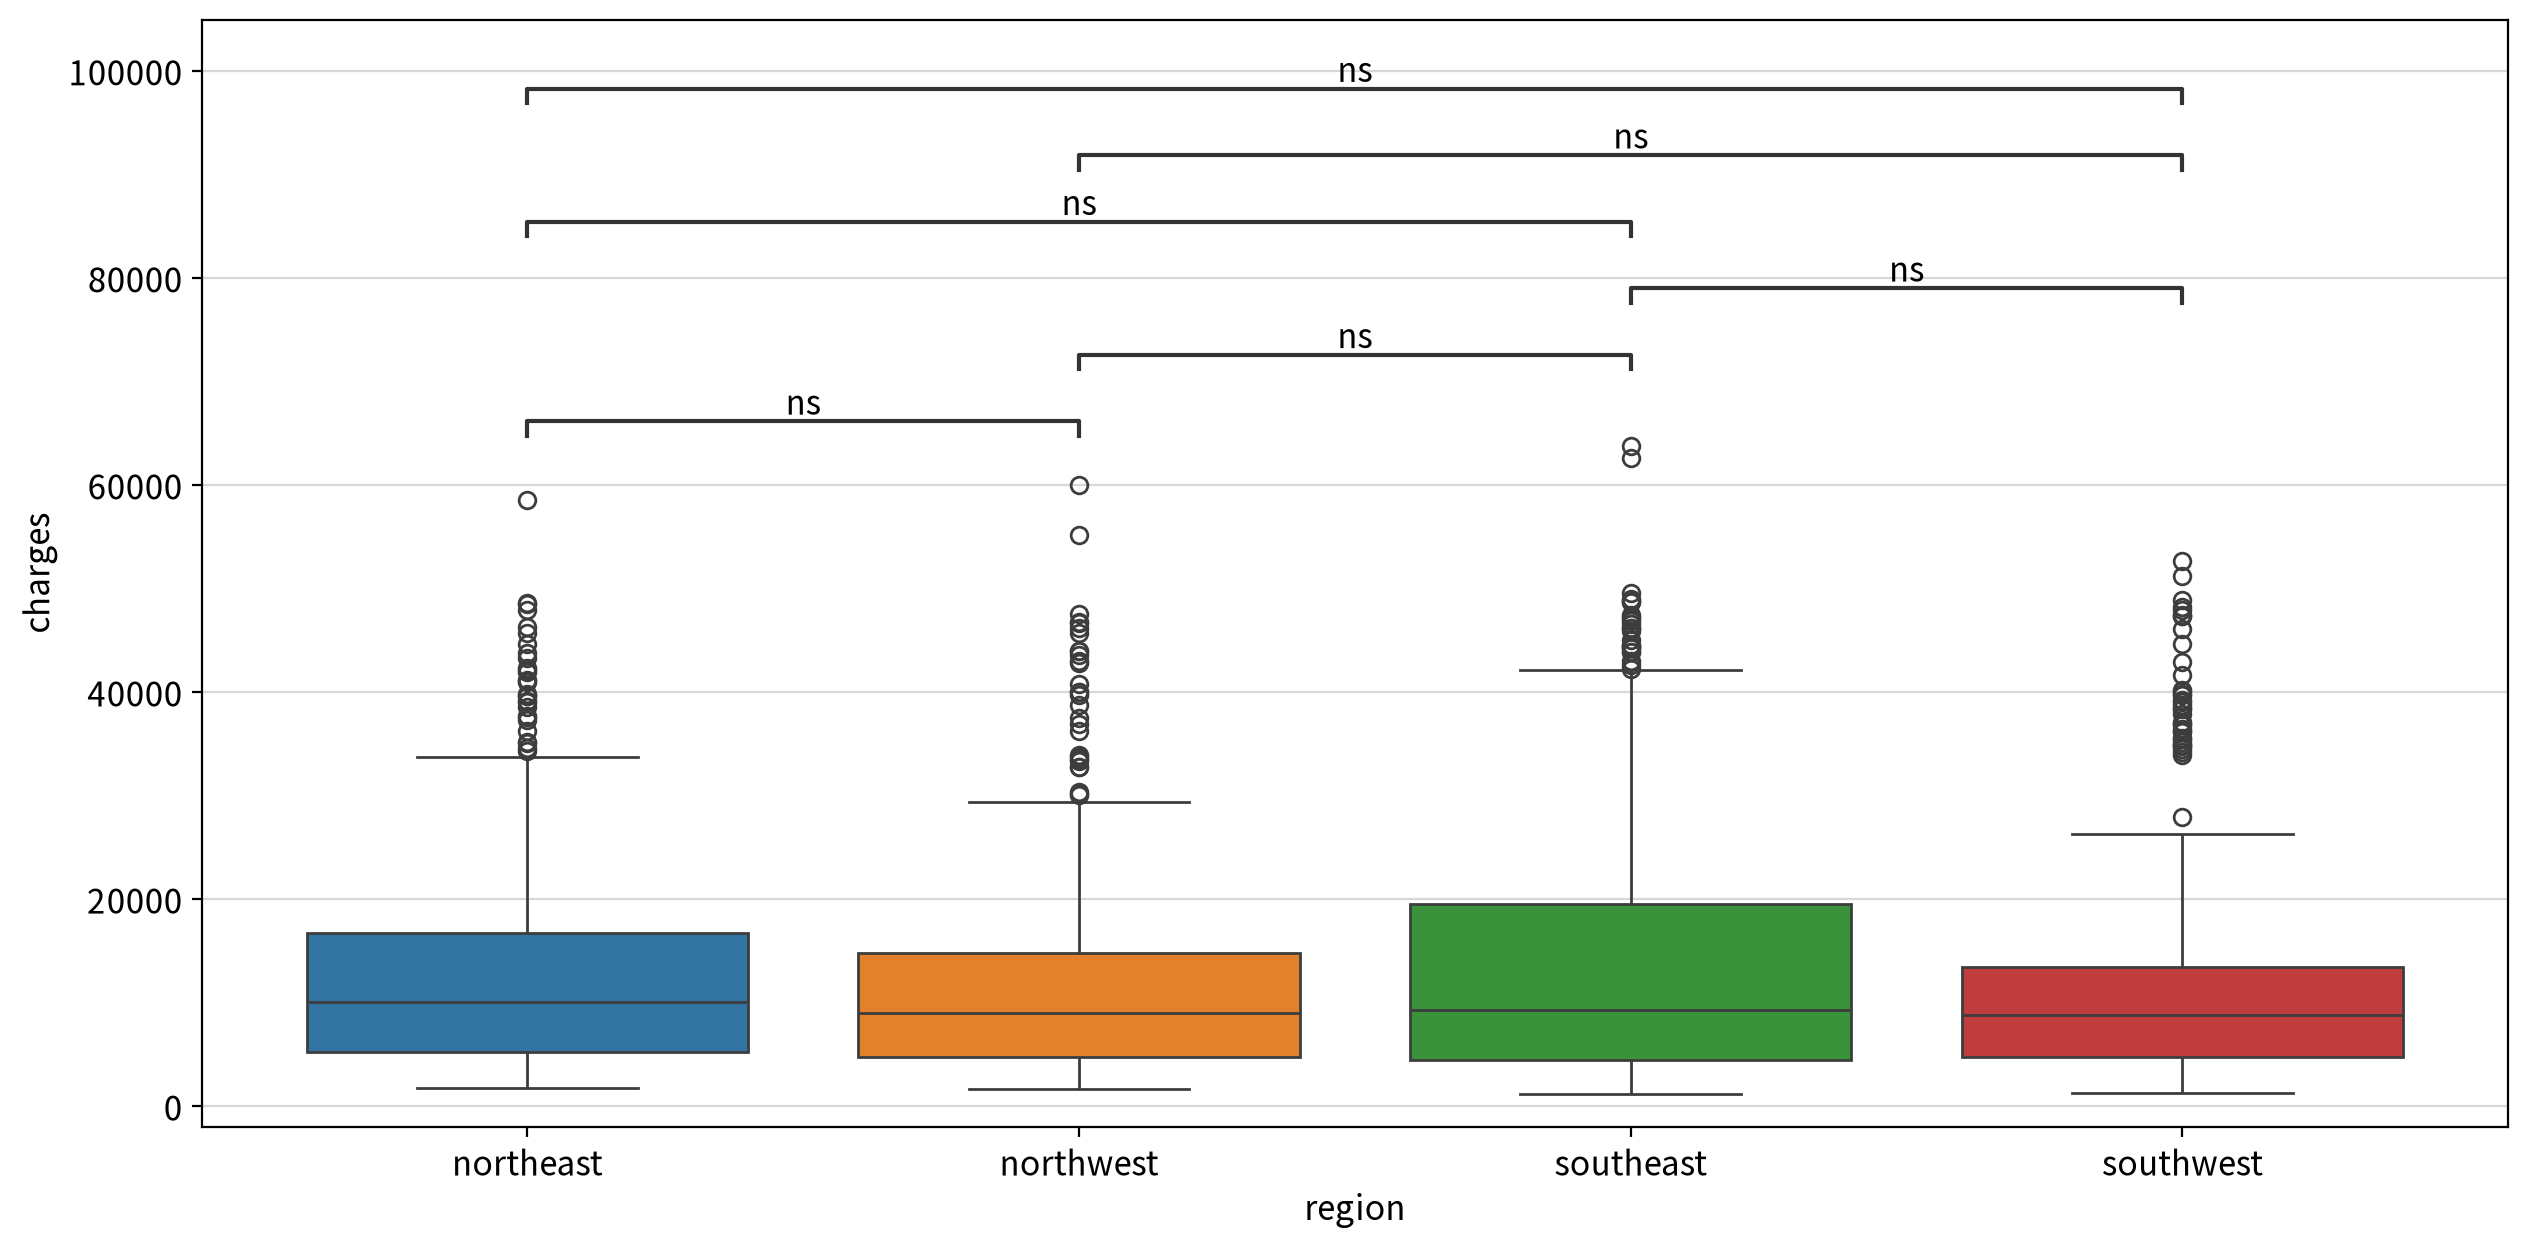

비교한 조합 쌍: 6개
유의한 쌍: 0개
평균 차이가 가장 큰 쌍: (southeast) vs (southwest)→ 차이 2388.475, 효과크기 Negligible, p=value 0.068
평균 차이가 가장 작은 쌍: (northwest) vs (southwest)→ 차이 103.903, 효과크기 Negligible, p-value 0.999


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,northeast,northwest,"13,406.384","12,450.841",955.543,877.192,1.089,645.827,0.696,0.085,False,Negligible
1,Games-Howell,northeast,southeast,"13,406.384","14,735.412","-1,329.028",962.948,-1.380,679.413,0.512,-0.104,False,Negligible
2,Games-Howell,northeast,southwest,"13,406.384","12,346.938","1,059.446",895.549,1.183,646.648,0.638,0.093,False,Negligible
3,Games-Howell,northwest,southeast,"12,450.841","14,735.412","-2,284.571",956.389,-2.389,677.137,0.080,-0.180,False,Negligible
4,Games-Howell,northwest,southwest,"12,450.841","12,346.938",103.903,888.492,0.117,645.983,0.999,0.009,False,Negligible
5,Games-Howell,southeast,southwest,"14,735.412","12,346.938","2,388.475",973.252,2.454,683.096,0.068,0.185,False,Negligible


In [90]:
for n in ['region']:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    # anova 분석은 long 타입으로 바로 투입 가능
    display(my_stats.anova_oneway(df, y=target, between=n))

    # 사후검정
    display(my_stats.posthoc_oneway(df, y=target, between=n))

> 💡 **인사이트 — 이변량 (region × charges)**
>
> - `region`은 등분산성이 위배돼 Welch ANOVA가 선택됐고, **유의하지 않았다**(p = 0.053). 효과크기도 np² = 0.007로 **Negligible**(Cohen 기준 0.01 미만)이다.
> - Games-Howell 사후검정에서도 **유의한 쌍이 하나도 없었다.** 효과크기와 사후검정 결과를 함께 보면, 지역은 청구비용을 설명하지 못한다고 판단할 수 있다.

### (4) 변수 채택 결과 표

- **채택 기준은 "각 독립변수 ↔ 종속변수(`charges`) 단독 관계"만 사용한다.**
  - 연속형 : 유의(p < 0.05) + 상관강도 Moderate 이상(|ρ| ≥ 0.3)
  - 명목형 : 집단 차이 유의(p < 0.05)
- 공선성(변수 간 중복)은 이 이변량 단계에서는 알 수 없으므로, 다음 다변량 분석과 PART 3의 VIF 단계에서 점검한다.
- 종합 판정 : **채택 2, 보류 2, 제외 2**
  - 보류로 판정된 변수는 일단 모델링에 투입하고, 회귀계수의 유의성으로 최종 채택 여부를 판정한다.
  - 제외로 판정된 변수는 집단 차이가 유의하지 않아 모델링에 투입하지 않는다.

| 채택여부 | 변수 | 검정방법 | 유의수준 (p) | 효과크기 | 가정점검 | 비대칭신호 | 근거 |
|---|---|---|---|---|---|---|---|
| ✅ 채택 | smoker | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 집단 차이 유의 (흡연자가 더 높음, 단측(no < yes) p < 0.001) |
| ✅ 채택 | age | Spearman | $< 0.001$ | ρ=+0.534 (중간) | 정규성 위배 / 선형성 충족 / 이상치 계수왜곡 있음 | 대칭 / 불필요 | 유의미한 상관 (\|ρ\|≥0.3, 설명력 1위) |
| 🟡 보류 | children | Spearman | $< 0.001$ | ρ=+0.132 (약함) | 정규성 위배 / 선형성 위배 / 이상치 계수왜곡 없음 | 우편향 / log1p 필요 (0 포함) | 유의하나 관계 약함 (\|ρ\|<0.3) → **모델링 투입 후 계수 유의성으로 최종 판정** |
| 🟡 보류 | bmi | Spearman | $< 0.001$ | ρ=+0.120 (약함) | 정규성 위배 / 선형성 충족 / 이상치 계수왜곡 있음 | 대칭 / 불필요 | 유의하나 관계 약함 (\|ρ\|<0.3) → **모델링 투입 후 계수 유의성으로 최종 판정** |
| ❌ 제외 | region | Welch ANOVA | $0.053$ | np²=0.007 (Negligible) | 등분산성 위배 → Welch ANOVA, Games-Howell 사후검정 | 해당 없음 | 집단 차이 유의하지 않음, 사후검정 유의한 쌍 0개 |
| ❌ 제외 | sex | Mann-Whitney U | $0.695$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 집단 차이 유의하지 않음 |

## 2-3. 다변량 분석 — 독립변수끼리 중복되는가?

### (1) 독립변수 간 상관

- |ρ| ≥ 0.7 인 **강한 상관 쌍**을 변수별로 묶어 보여 준다.

In [91]:
corr_x = my_stats.multi_correlation(data=df, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr_x)

,age,bmi,children
age,1.000,0.108,0.056
bmi,0.108,1.000,0.016
children,0.056,0.016,1.000


,max-y,max-coef,count,columns
x,,,,
age,bmi,0.108,0,-
bmi,age,0.108,0,-
children,age,0.056,0,-


> 💡 **인사이트 — 다변량**
>
> - 연속형 독립변수끼리는 **강한 상관 쌍이 하나도 없다**(|ρ| ≥ 0.7 인 쌍 0개). 가장 강한 쌍도 `age` ↔ `bmi`(ρ = +0.108)로 거의 무관하다.
> - 세 변수는 **서로 다른 정보**를 담고 있다. 같은 정보를 여러 변수가 나눠 갖는 구조가 아니라서, 공선성 때문에 후보로 내릴 변수는 없다.
> - 다만 이 단계에서 변수를 실제로 제거하지는 않는다. 실제 VIF가 문제 수준인지는 PART 3의 `vif=True` 체크포인트에서 확인한다.

### (2) 흡연 여부에 따라 관계가 달라지는가? — 상호작용 탐색

- 청구비용 분포의 '고비용 덩어리'가 어디서 오는지, 흡연 여부로 색을 나눠 다시 본다.
- 비만 기준은 **WHO 성인 비만 기준(BMI ≥ 30)** 을 따랐다.

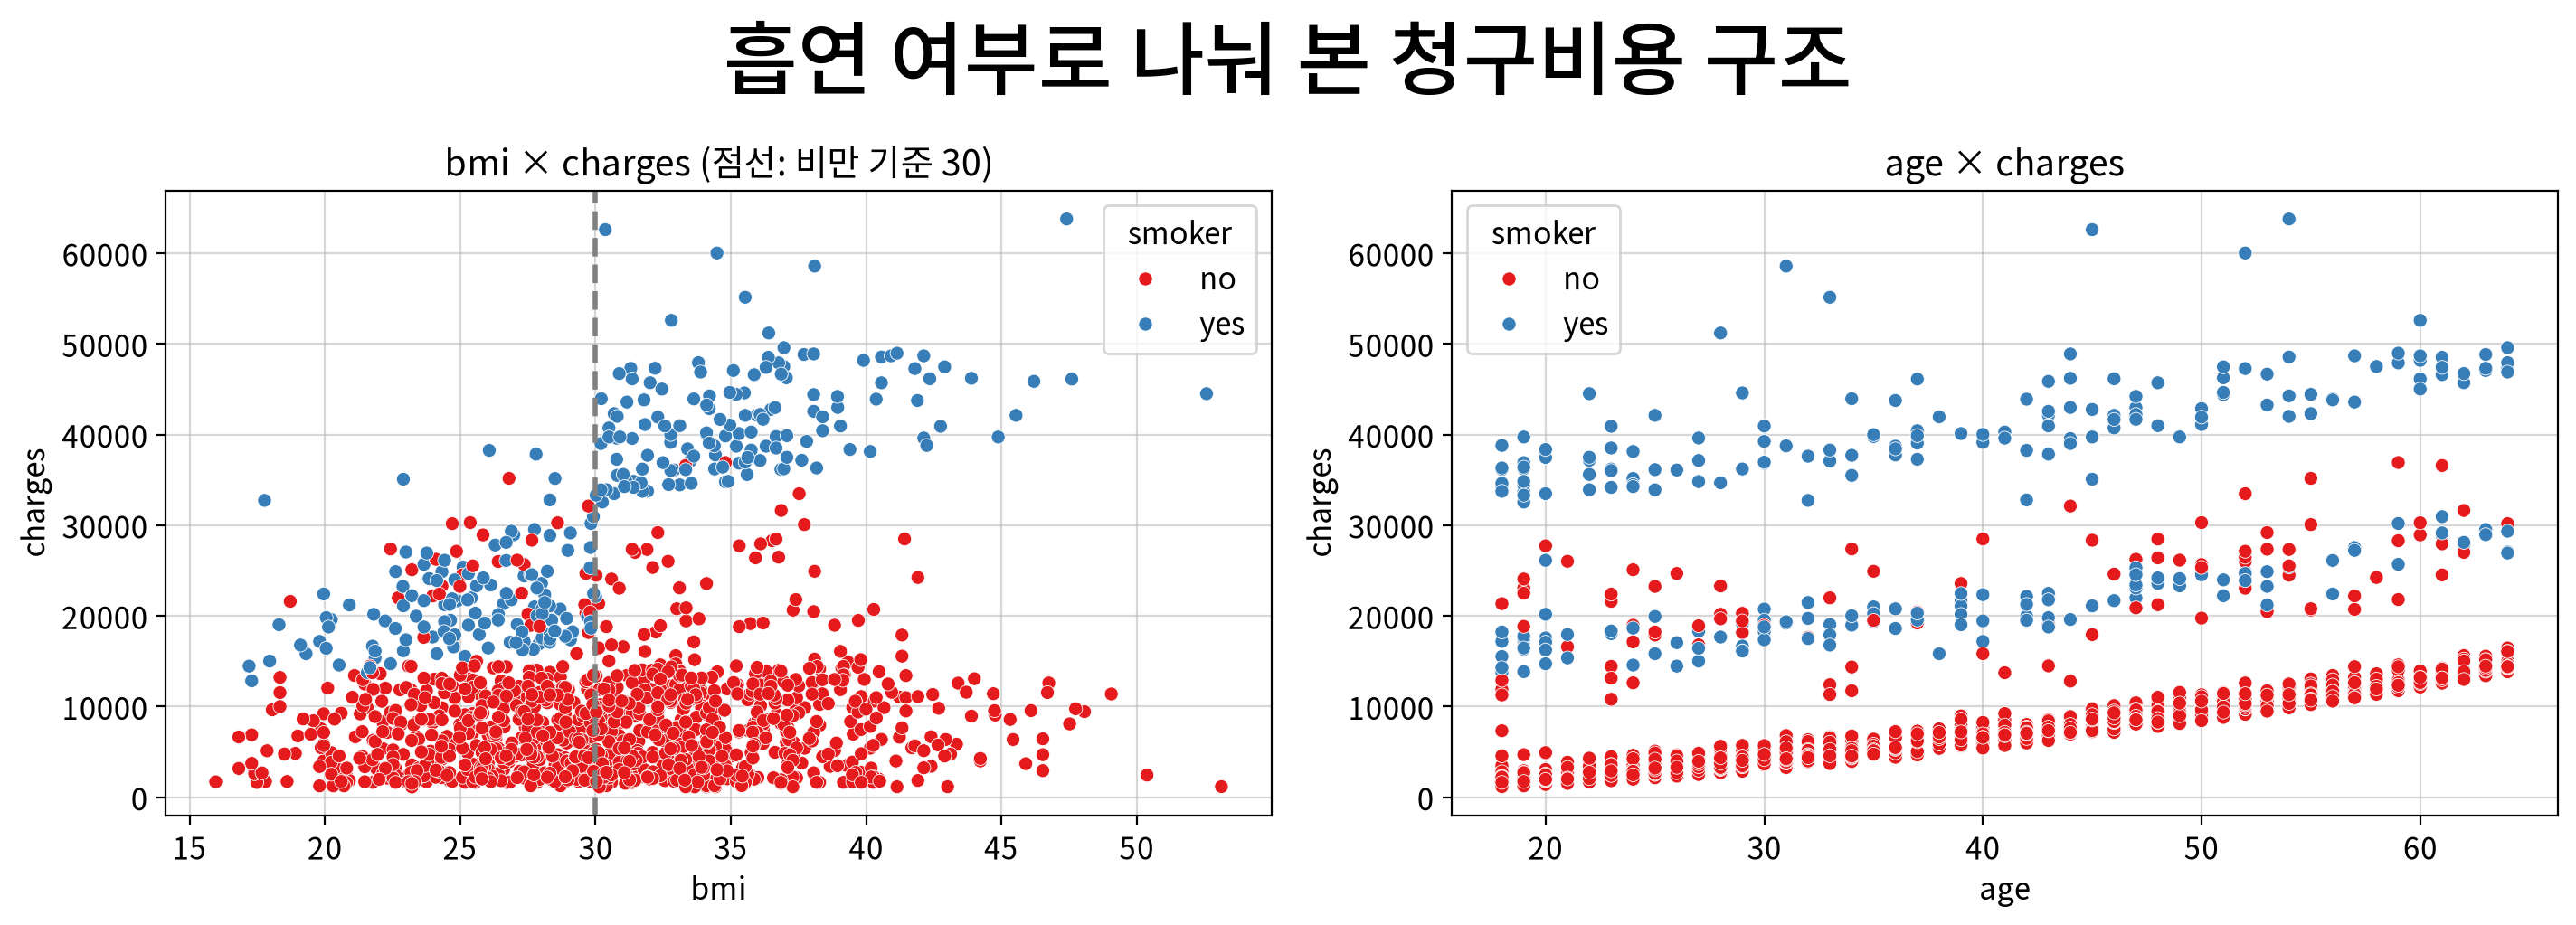

In [92]:
fig, ax = my_plot.init(rows=1, cols=2, width=720, height=520, title="흡연 여부로 나눠 본 청구비용 구조")
my_plot.scatterplot(data=df, x="bmi", y=target, hue="smoker", palette="Set1", 
                    s=30, linewidth=0.3, outline=False, ax=ax[0])
my_plot.scatterplot(data=df, x="age", y=target, hue="smoker", palette="Set1", 
                    s=30, linewidth=0.3, outline=False, ax=ax[1])
ax[0].axvline(30, color="gray", linestyle="--")
ax[0].set_title("bmi × charges (점선: 비만 기준 30)", fontsize=14)
ax[1].set_title("age × charges", fontsize=14)
my_plot.show()

In [93]:
# 흡연 × 비만(BMI ≥ 30) 네 집단의 평균 청구비용
obese = df["bmi"] >= 30                                  # 비만이면 True, 아니면 False
df.groupby(["smoker", obese])[target].mean().unstack()  

bmi,False,True
smoker,,
no,"7,977.029","8,855.531"
yes,"21,363.217","41,557.988"


> 💡 **인사이트 — 상호작용 탐색 (이 분석의 핵심 발견)**
>
> - 독립변수끼리는 상관이 거의 없었지만, 흡연 여부로 색을 나누자 숨어 있던 구조가 드러났다. **BMI(비만)의 영향은 흡연자에게서 훨씬 크게 나타난다.**
>
> | | 비만 아님 (BMI < 30) | 비만 (BMI ≥ 30) | 차이 |
> |---|---|---|---|
> | 비흡연자 | 7,977 | 8,856 | +879 (+11%) |
> | **흡연자** | 21,363 | **41,558** | **+20,195 (+95%)** |
>
> - 비흡연자는 비만이어도 비용이 거의 그대로지만(+879달러), **흡연자는 비만이면 비용이 두 배**가 된다(+20,195달러).
> - 흡연 효과와 비만 효과가 단순히 더해지는 것이라면, 흡연·비만 집단의 비용은 약 22,242달러(흡연·정상 21,363 + 비만 효과 879)여야 한다. 실제로는 41,558달러로 약 19,316달러가 더 많다. **흡연이 비만의 영향을 키우는 상호작용(interaction)** 이다.
> - `age` 산점도는 **세 개의 띠**로 나뉜다. 비흡연자는 맨 아래 띠에 있고, 흡연자는 가운데 · 위 두 띠로 갈린다. 피벗표의 흡연 · 정상(평균 약 21,000달러)과 흡연 · 비만(약 42,000달러)이 두 띠의 높이와 맞아, **흡연자 안의 두 띠는 비만 여부로 갈린 것으로 보인다.**
> - 세 띠 모두 나이가 들수록 **위로 휘어지며** 올라간다 → 나이 효과는 곡선이다.
> - 단순 덧셈 모델(`age + bmi + smoker`)로는 이 구조를 담을 수 없다. → PART 3에서 파생변수로 직접 넣는다.

## 2-4. 최종 변수 선택

- **EDA 판정 기준**
  - 이변량 : 유의(p < 0.05) + |ρ| ≥ 0.3 → ✅ 채택, 유의하지만 |ρ| < 0.3 → 🟡 보류, 유의하지 않음 → ❌ 제외
  - 다변량 : |ρ| ≥ 0.7로 얽힌 쌍이 없어(최대 `age` ↔ `bmi` ρ = +0.108) 공선성 때문에 후보로 내릴 변수는 없다
  - 상호작용 : 흡연 여부에 따라 효과가 달라지는 변수는 PART 3에서 **파생변수**로 만든다

| EDA 판정 | 변수 | 검정방법 | 유의수준 | 효과크기 | 가정점검 | 비대칭신호 | 중복 (\|ρ\| ≥ 0.7) | EDA 근거 | 파생변수 근거 |
|---|---|---|---|---|---|---|---|---|---|
| ✅ 채택 | smoker | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 해당 없음 | 흡연자가 압도적으로 높음 → 더미로 투입 | `bmi`와 상호작용 → `smoker_obese` |
| ✅ 채택 | age | Spearman | $< 0.001$ | ρ=+0.534 (중간) | 정규성 위배 / 선형성 충족 / 이상치 왜곡 있음 | 대칭 / 불필요 | 없음 | 단독 설명력 1위 (연속형) | 산점도의 띠가 위로 휘어짐 → `age2` |
| 🟡 보류 | children | Spearman | $< 0.001$ | ρ=+0.132 (약함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log1p | 없음 | 관계 약함 (\|ρ\| < 0.3), 이산형 | — |
| 🟡 보류 | bmi | Spearman | $< 0.001$ | ρ=+0.120 (약함) | 정규성 위배 / 선형성 충족 / 이상치 왜곡 있음 | 대칭 / 불필요 | 없음 | 관계 약함 (\|ρ\| < 0.3) | **흡연자에게서 효과가 훨씬 큼** (비만 시 +95%) → `smoker_obese` |
| ❌ 제외 | region | Welch ANOVA | $0.053$ | np²=0.007 (Negligible) | 등분산성 위배 → Welch ANOVA, Games-Howell | 해당 없음 | 해당 없음 | 집단 차이 유의하지 않음, 사후검정 유의한 쌍 0개 | — |
| ❌ 제외 | sex | Mann-Whitney U | $0.695$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 해당 없음 | 집단 차이 유의하지 않음 | — |

<br>

> 💡 **인사이트 — EDA 판정 요약**
>
> - **채택 2개, 보류 2개, 제외 2개.** 모델에는 채택 · 보류 4개(`smoker` · `age` · `bmi` · `children`)를 투입하고, 제외한 `sex` · `region`은 넣지 않는다.
> - 보류 변수는 EDA에서 지우지 않는다. 특히 `bmi`는 단독 상관이 약했지만(ρ = +0.120), 흡연 여부로 나눠 보면 **흡연자에게서 훨씬 큰 효과가 있었다.** 단독 관계만 보고 지웠다면 이 노트북의 핵심 구조를 놓쳤을 것이다.
> - 보스턴과 달리 독립변수끼리 얽힌 덩어리가 없어 공선성 문제는 작을 것으로 예상된다. 대신 **변수 간 '곱해지는' 관계(상호작용)** 가 핵심이므로, PART 3에서 기계적 전처리와 파생변수 모델을 함께 비교한다.

---
# PART 3. 회귀모델링

### (1) EDA 결과 반영

- 이변량 분석에서 유의하지 않은 `sex`, `region`을 제외한 데이터로 모델링한다.

In [94]:
drop_cols = ["sex", "region"]
df2 = df.drop(columns=drop_cols)
nominal_cols2 = [c for c in nominal_cols if c not in drop_cols]
print("모델 투입 변수 :", df2.columns.drop(target).tolist())

모델 투입 변수 : ['age', 'bmi', 'children', 'smoker']


### (2) 전처리 체크포인트 정의

In [95]:
checkpoints = {
    "0_기준선":     dict(),
    "1_로그변환":   dict(log=True),
    "2_이상치대체": dict(log=True, outlier=True),
    "3_공선성제거": dict(log=True, outlier=True, vif=True),
    "4_스케일링":   dict(log=True, outlier=True, vif=True, scale=True),
}

### (3) 체크포인트별 적합

In [96]:
fits = {}

for name in checkpoints:           # 딕셔너리를 반복문에 설정하면 key에 대한 반복이 수행된다
    print(f"\n▶︎ --- {name} ---")

    # 전처리 + 모델 적합을 한 번에 수행한다 
    # -> name 을 지정해 두면 compare_models 의 결과표에 그대로 사용된다
    fits[name] = my_ols.fit_pipeline(data=df2, y=target, 
                                    nominal_cols=nominal_cols2, name=name, verbose=False, 
                                    **checkpoints[name])


▶︎ --- 0_기준선 ---


▶︎ --- 1_로그변환 ---


▶︎ --- 2_이상치대체 ---


▶︎ --- 3_공선성제거 ---

완료! 남은 변수: ['age', 'bmi', 'children']
최대 VIF = 1.01


▶︎ --- 4_스케일링 ---

완료! 남은 변수: ['age', 'bmi', 'children']
최대 VIF = 1.01



### (4) 성능 비교

In [97]:
best = my_ols.compare_models(fits)
print("선택된 모델 :", best.name_)

,변수 수,R²(모델척도),Adj.R²,AIC,BIC,R²(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
0_기준선,4,0.750,0.749,"27,092.752","27,118.743",0.750,"6,058.642","4,181.335",0.000
4_스케일링,4,0.763,0.762,"1,652.808","1,678.799",0.532,"8,278.466","4,248.575",36.640
2_이상치대체,4,0.763,0.762,"1,652.808","1,678.799",0.532,"8,278.466","4,248.575",36.640
3_공선성제거,4,0.763,0.762,"1,652.808","1,678.799",0.532,"8,278.466","4,248.575",36.640
1_로그변환,4,0.763,0.762,"1,653.311","1,679.302",0.532,"8,281.268","4,247.790",36.690


선택된 모델 : 0_기준선


> 💡 **인사이트 — 전처리 비교: 로그변환이 오히려 손해였다**
>
> - 로그변환 모델은 모델 척도 R²가 0.750 → 0.763으로 **좋아 보였지만**, 예측값을 달러로 되돌리면 **R²은 0.750 → 0.532, RMSE는 6,059 → 8,281로 크게 악화**됐다.
> - **품질 점검의 '로그변환 필요' 판정은 검토 대상이지 정답이 아니다.** → 기계적 전처리 중 최선은 `0_기준선`(RMSE 6,059, R² 0.750).

### (5) 도메인 파생변수 만들기 — 흡연 × 비만 상호작용

- EDA에서 본 구조를 변수로 만든다.
  - `smoker_obese` : 흡연자이면서 BMI ≥ 30(WHO 비만 기준)이면 1 (**상호작용항**)
  - `age2` : 나이의 제곱 (나이가 들수록 비용이 **가속**되는 곡선을 반영)

In [98]:
df3 = df2.copy()
df3["smoker_obese"] = ((df3["smoker"] == "yes") & (df3["bmi"] >= 30)).astype(int)   # 흡연 × 비만
df3["age2"] = df3["age"] ** 2    

### (6) 파생변수 데이터의 체크포인트 정의

- 기준선과 로그변환만 비교하고, 아래 세 단계는 제외한다.
  - **이상치 대체** : 0/1 변수인 `smoker_obese`는 IQR 경계가 0이 되어, 1이 모두 0으로 바뀐다(핵심 변수 소실).
  - **공선성 제거** : 독립변수 간 강한 상관이 없고(최대 ρ = 0.108), `age`와 `age2`의 중복은 후진소거가 정리한다.
  - **스케일링** : OLS 성능은 바뀌지 않고, 0/1 변수의 해석만 어려워진다.

In [100]:
domain_checkpoints = {
    "5_도메인_기준선":     dict(),
    "6_도메인_로그변환":   dict(log=True),
}

### (7) 파생변수 모델 적합 (`fits` 에 누적)

- 앞에서 만든 `fits` 딕셔너리에 **이어서 담아야** 두 방식을 한 표에서 비교할 수 있다.
- `**`는 딕셔너리를 풀어서 키워드 인자(이름=값)로 넘기는 문법이다.

In [101]:
for name in domain_checkpoints:
    print(f"\n▶︎ --- {name} ---")

    # fits 에 누적하므로 앞의 5개 모델과 함께 비교된다.
    fits[name] = my_ols.fit_pipeline(data=df3, y=target, 
                                     nominal_cols=nominal_cols2, 
                                     name=name, verbose=False, **domain_checkpoints[name])

print("\n누적된 모델 :", len(fits), "개")


▶︎ --- 5_도메인_기준선 ---

유의하지 않은 독립변수 제거 → age (p = 0.6882)

▶︎ --- 6_도메인_로그변환 ---

유의하지 않은 독립변수 제거 → bmi (p = 0.3218)

누적된 모델 : 7 개


### (8) 전체 모델 성능 비교

In [102]:
final_fit = my_ols.compare_models(fits)

print("최종 모델 :", final_fit.name_)
print("독립변수  :", int(final_fit.df_model), "개")

,변수 수,R²(모델척도),Adj.R²,AIC,BIC,R²(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
5_도메인_기준선,5,0.864,0.863,"26,279.036","26,310.226",0.864,"4,465.724","2,447.386",0.000
0_기준선,4,0.750,0.749,"27,092.752","27,118.743",0.750,"6,058.642","4,181.335",35.670
4_스케일링,4,0.763,0.762,"1,652.808","1,678.799",0.532,"8,278.466","4,248.575",85.380
3_공선성제거,4,0.763,0.762,"1,652.808","1,678.799",0.532,"8,278.466","4,248.575",85.380
2_이상치대체,4,0.763,0.762,"1,652.808","1,678.799",0.532,"8,278.466","4,248.575",85.380
1_로그변환,4,0.763,0.762,"1,653.311","1,679.302",0.532,"8,281.268","4,247.790",85.440
6_도메인_로그변환,5,0.784,0.783,"1,531.756","1,562.945",0.528,"8,313.897","4,061.922",86.170


최종 모델 : 5_도메인_기준선
독립변수  : 5 개


> 💡 **인사이트 — 도메인 파생변수의 효과**
>
> | 모델 | 변수 수 | RMSE | R²(원본척도) |
> |---|---|---|---|
> | 0_기준선 (기계적 전처리 중 최선) | 4 | 6,059 | 0.750 |
> | **5_도메인_기준선** | **5** | **4,466** | **0.864** |
> | 6_도메인_로그변환 | 5 | 8,314 | 0.528 |
>
> - 파생변수 2개(`smoker_obese`, `age2`)를 넣자 **RMSE가 6,059 → 4,466으로 1,593달러(26.3%) 줄었다.** 어떤 전처리 조합보다 큰 개선이다.
> - `age2`를 함께 넣자 후진소거가 `age`를 제거했다(p = 0.688). 나이 효과는 **곡선 형태(`age2`) 하나로 충분히 설명**됐다. 산점도에서 청구비용이 나이에 따라 위로 휘어지며 올라가던 모습과 일치한다.
> - 파생변수 데이터에서도 **로그변환은 오히려 손해**였다(RMSE 8,314). 문제는 치우친 분포가 아니라 섞여 있는 집단이었고, 그 구조는 파생변수가 이미 담았다.

### (9) EDA 판정 vs 모델 결과

| 변수 | EDA 판정 | 모델 결과 |
|---|---|---|
| `smoker` | ✅ 채택 | ✅ 유지 |
| `age` | ✅ 채택 | 🔄 `age2`로 대체 (후진소거로 `age` 제거) |
| `bmi` | 🟡 보류 | ✅ 유지 |
| `children` | 🟡 보류 | ✅ 유지 |
| `sex` · `region` | ❌ 제외 | — 미투입 |
| `smoker_obese` | (파생변수) | ✅ 유지 |
| `age2` | (파생변수) | ✅ 유지 |

<br>

> 💡 **인사이트 — EDA 판정은 모델에서 어떻게 확인됐나**
>
> - 보류했던 `bmi` · `children`은 **모두 모델에 남았다.** 단독 상관이 약해도(ρ = +0.120, +0.132) 다른 변수를 통제하면 고유한 설명력이 있었다. EDA에서 바로 지웠다면 놓쳤을 변수다.
> - 채택했던 `age`는 **`age2`로 대체**됐다. 변수 자체가 아니라 '어떤 형태로 넣느냐'가 중요했다.
> - EDA에서 발견한 상호작용(`smoker_obese`)이 모델에 그대로 들어가, **EDA → 파생변수 → 모델**로 이어지는 흐름이 확인됐다.

### (10) 최종 모델 보고

## 최종 모델: 5_도메인_기준선

### ▶ 성능 보고

#### 1) 모형 적합도

**[Note] n = 1337. F(5, 1331) = 1690.0, p < 0.001, R² = 0.864, Adj.R² = 0.863, Durbin-Watson = 2.066**

charges를 종속변수로, bmi, children, smoker, smoker_obese, age2(을)를 독립변수로한 다중선형회귀분석 결과, 모형은 통계적으로 유의하였다.

> F(5, 1331) = 1690.0, p < 0.001, R² = 0.864.

즉, bmi, children, smoker, smoker_obese, age2는 charges의 약 86.39%를 설명하는 것으로 나타났다.

#### 2) 회귀계수 보고표

,종속변수,독립변수,B,표준오차,β,t,유의확률,VIF,공차
0,charges,smoker_obese,"19,338.067",585.183,0.497,33.046,0.000,2.210,0.453
1,charges,smoker,"13,606.395",433.083,0.454,31.418,0.000,2.040,0.490
2,charges,age2,3.336,0.110,0.310,30.452,0.000,1.014,0.986
3,charges,children,652.121,101.592,0.065,6.419,0.000,1.000,1.000
4,charges,bmi,46.241,21.818,0.023,2.119,0.034,1.182,0.846


#### 3) 영향력 순위 시각화 (표준화 계수 β)

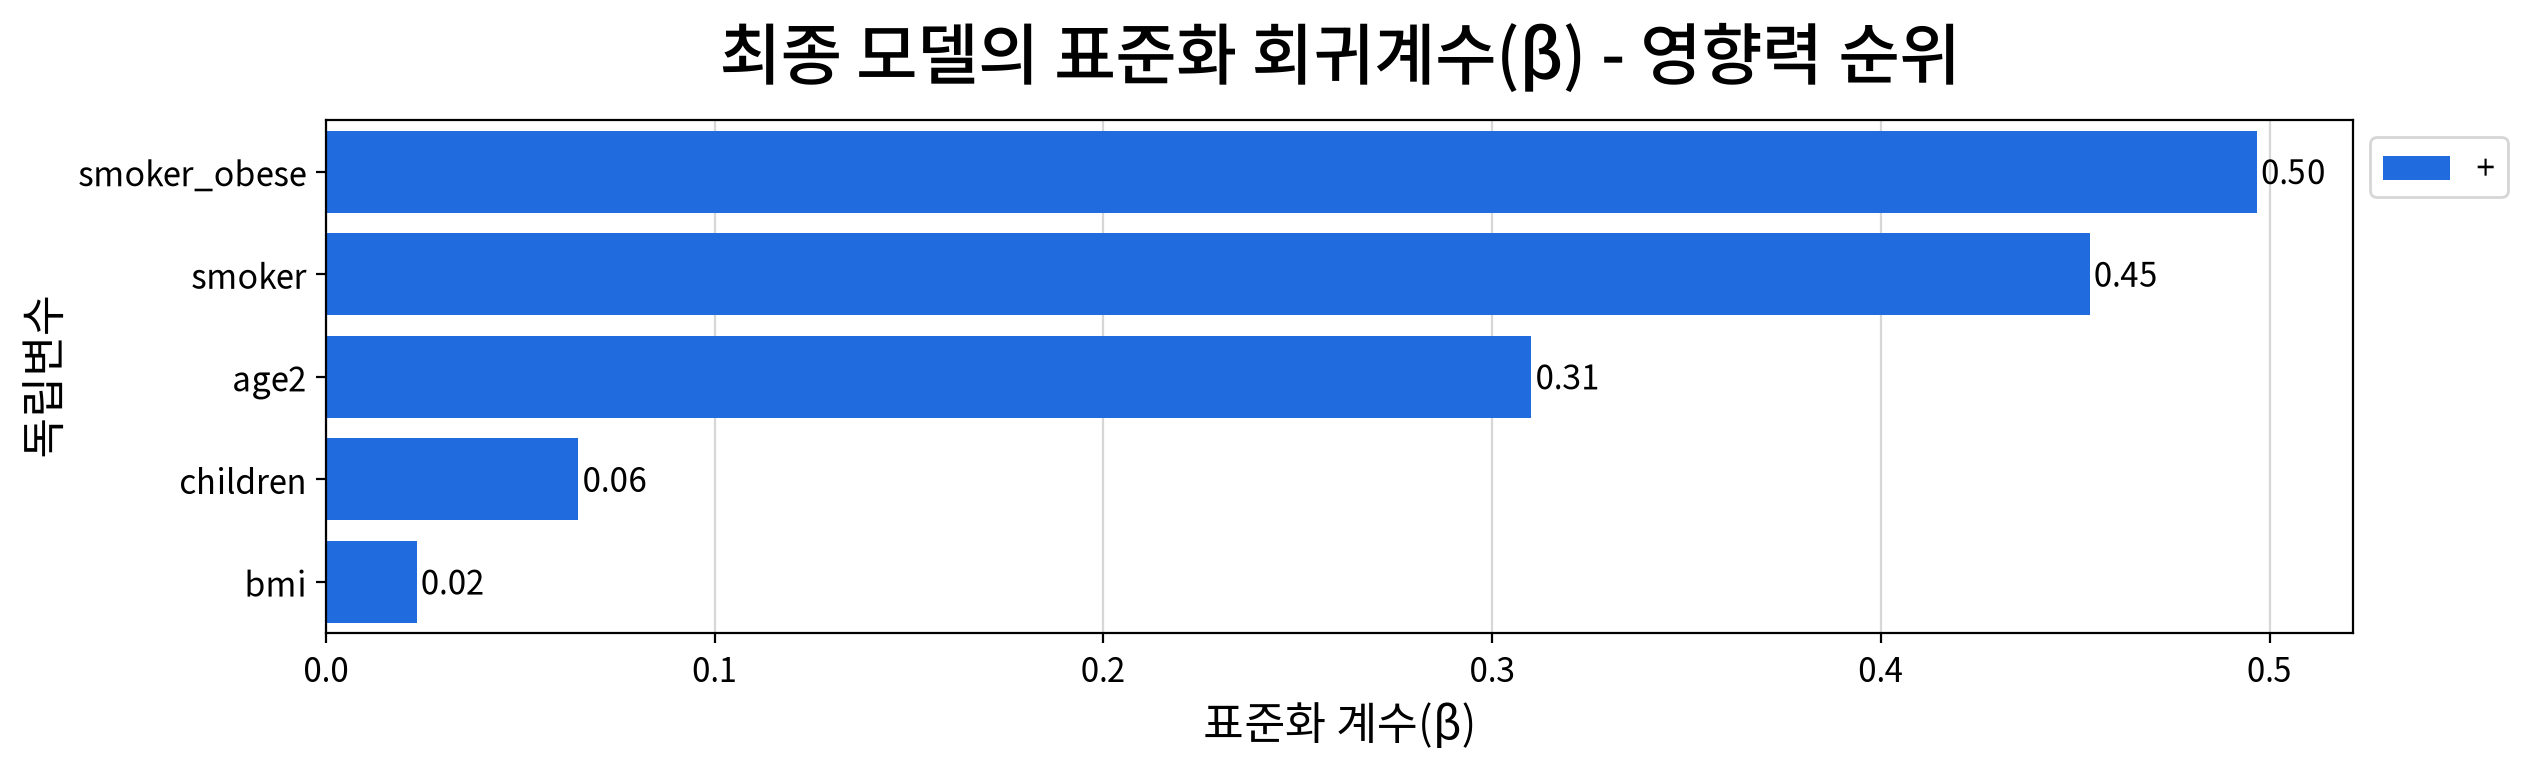

#### 4) 회귀계수 해석 문장

- **bmi** 의 회귀계수는 **B = 46.24** 으로 나타났으며, 이는 **charges** 에 유의한 요인임을 의미한다. (**t(1331) = 2.12**, **p = .034**) 즉, bmi가 **1 증가**할 때 charges는 평균적으로 **46.24 증가**하는 것으로 해석된다.
- **children** 의 회귀계수는 **B = 652.12** 으로 나타났으며, 이는 **charges** 에 유의한 요인임을 의미한다. (**t(1331) = 6.42**, **p < .001**) 즉, children가 **1 증가**할 때 charges는 평균적으로 **652.12 증가**하는 것으로 해석된다.
- **smoker** 의 회귀계수는 **B = 13606.4** 으로 나타났으며, 이는 **charges** 에 유의한 요인임을 의미한다. (**t(1331) = 31.42**, **p < .001**) 즉, smoker가 **1 증가**할 때 charges는 평균적으로 **13606.40 증가**하는 것으로 해석된다.
- **smoker_obese** 의 회귀계수는 **B = 19338.07** 으로 나타났으며, 이는 **charges** 에 유의한 요인임을 의미한다. (**t(1331) = 33.05**, **p < .001**) 즉, smoker_obese가 **1 증가**할 때 charges는 평균적으로 **19338.07 증가**하는 것으로 해석된다.
- **age2** 의 회귀계수는 **B = 3.34** 으로 나타났으며, 이는 **charges** 에 유의한 요인임을 의미한다. (**t(1331) = 30.45**, **p < .001**) 즉, age2가 **1 증가**할 때 charges는 평균적으로 **3.34 증가**하는 것으로 해석된다.

---

### ▶ 회귀모형 가정 검정

#### 1) 선형성 검정

,statistic,p-value,linearity,result
Ramsey RESET,0.077,0.782,True,귀무가설 채택 → 선형성 위배 근거 없음


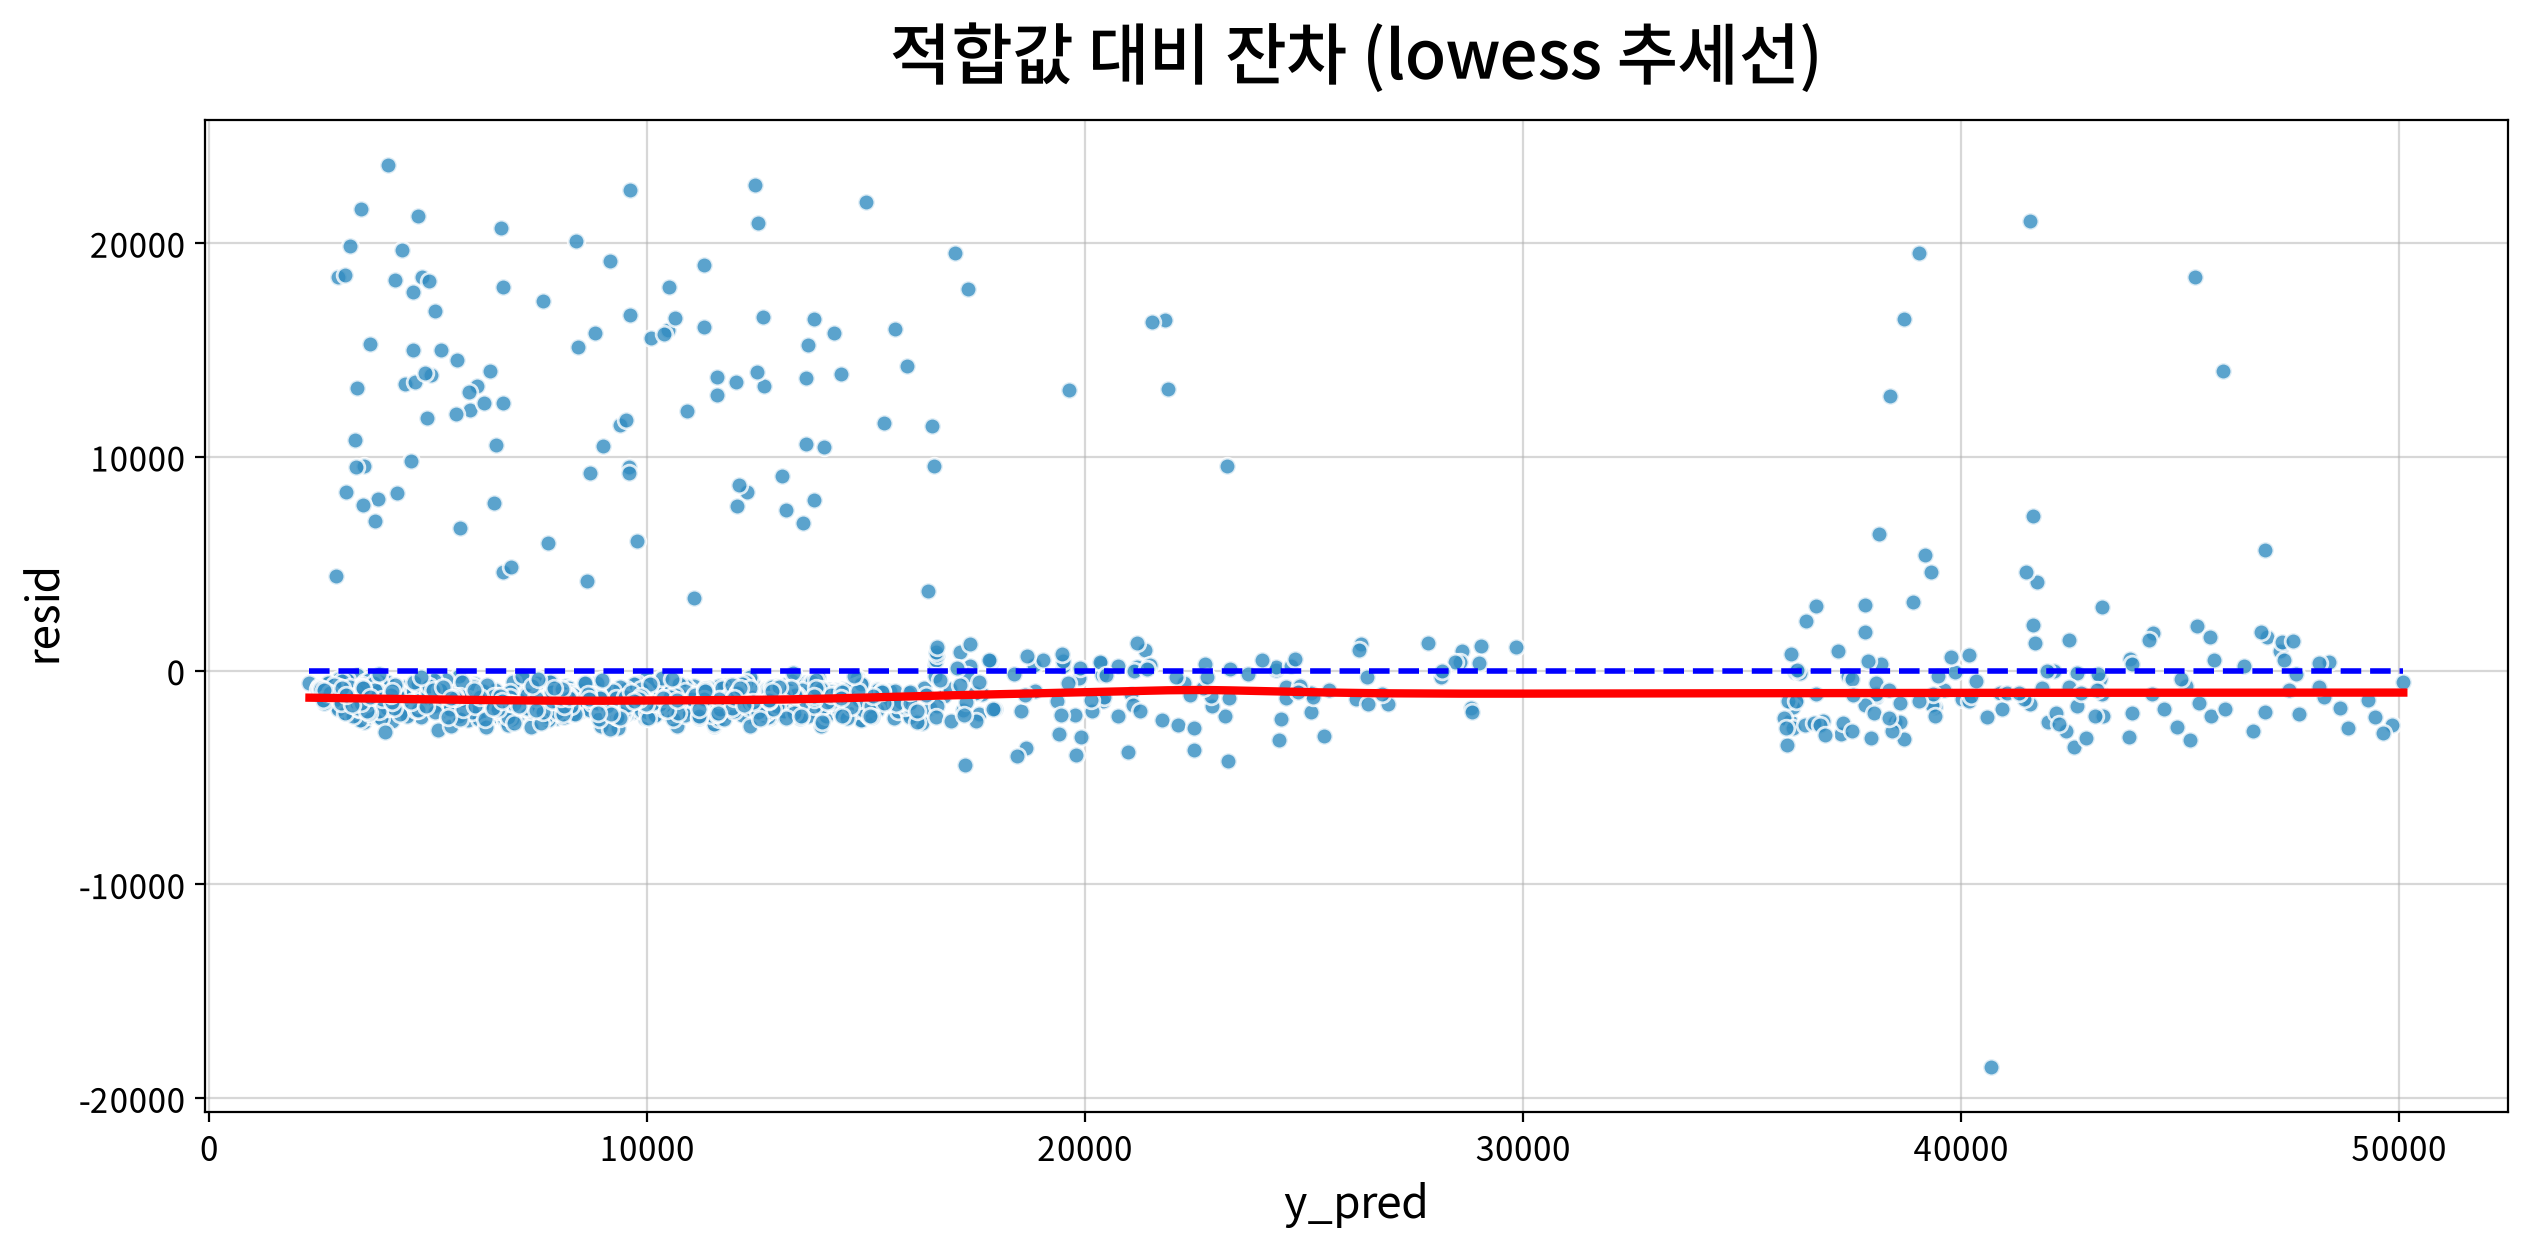

#### 2) 정규성 검정

▶ 검정통계량을 이용한 정규성 검정

,statistic,p-value,normality,result
Kolmogorov-Smirnov,0.363,0.000,False,대립가설 채택 → 정규성 위배


▶ Q-Q 플롯을 이용한 정규성 검정

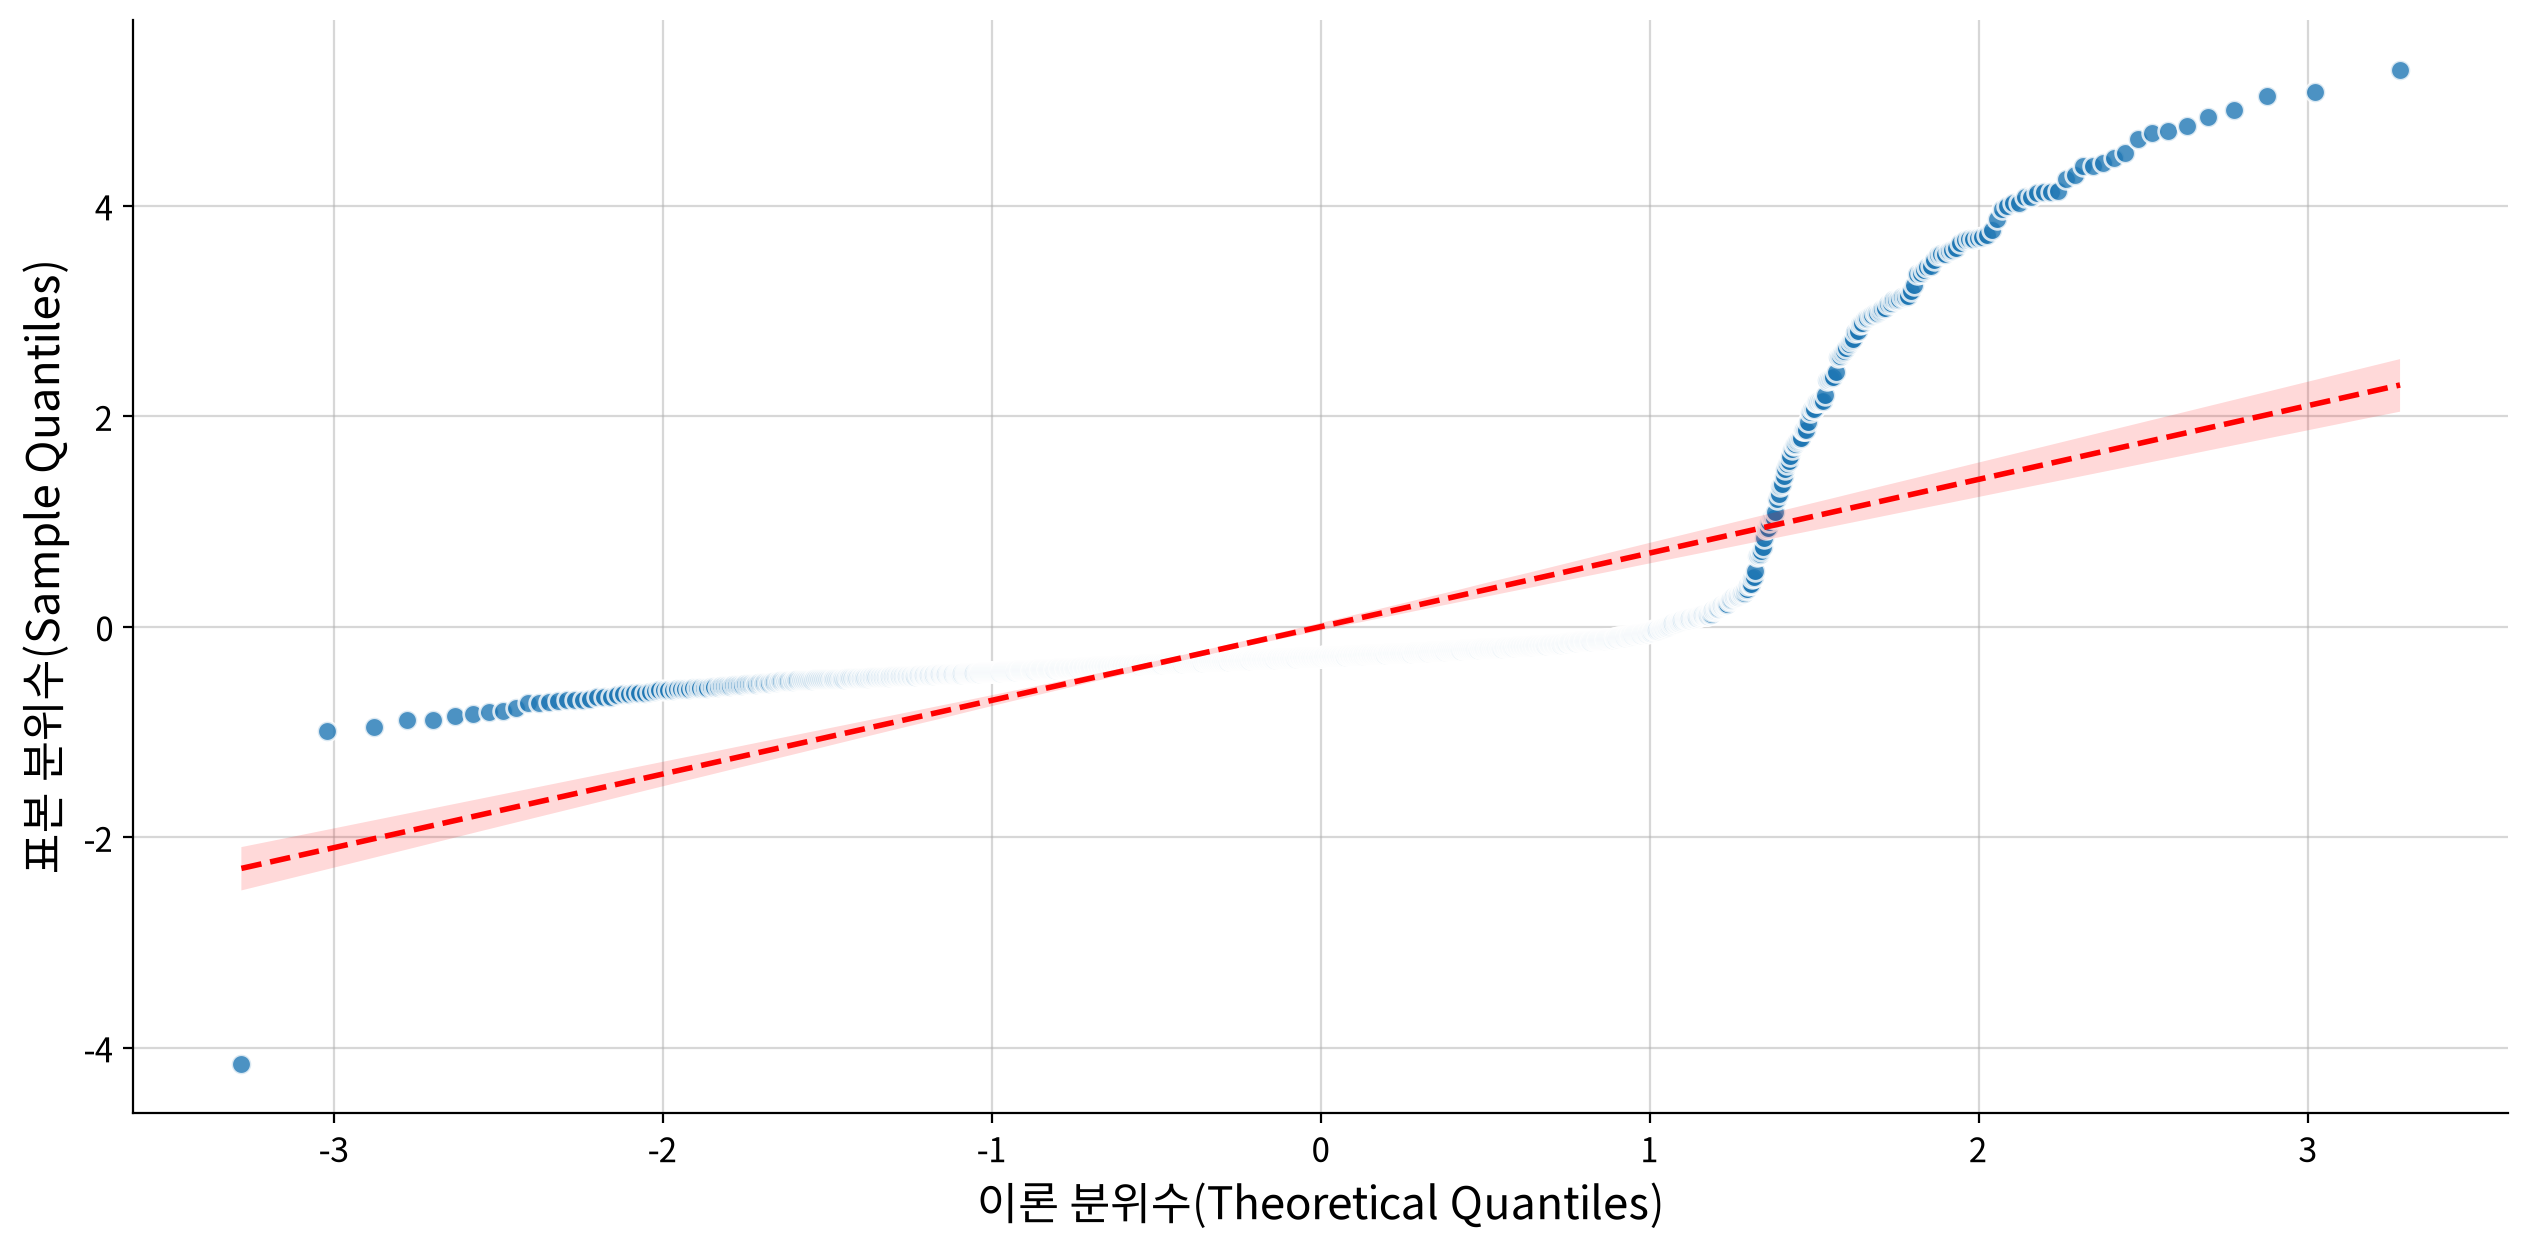

▶ √MSE 구간 규칙을 이용한 정규성 검정

,기대(%),허용 구간(%),실제(%),판정
구간,,,,
±1√MSE,68.000,65~71,91.320,위배
±2√MSE,95.000,94~96,93.040,위배
±3√MSE,99.700,99~100,95.510,위배


√MSE = 4475.78 · 구간 규칙 판정: 정규성 위배


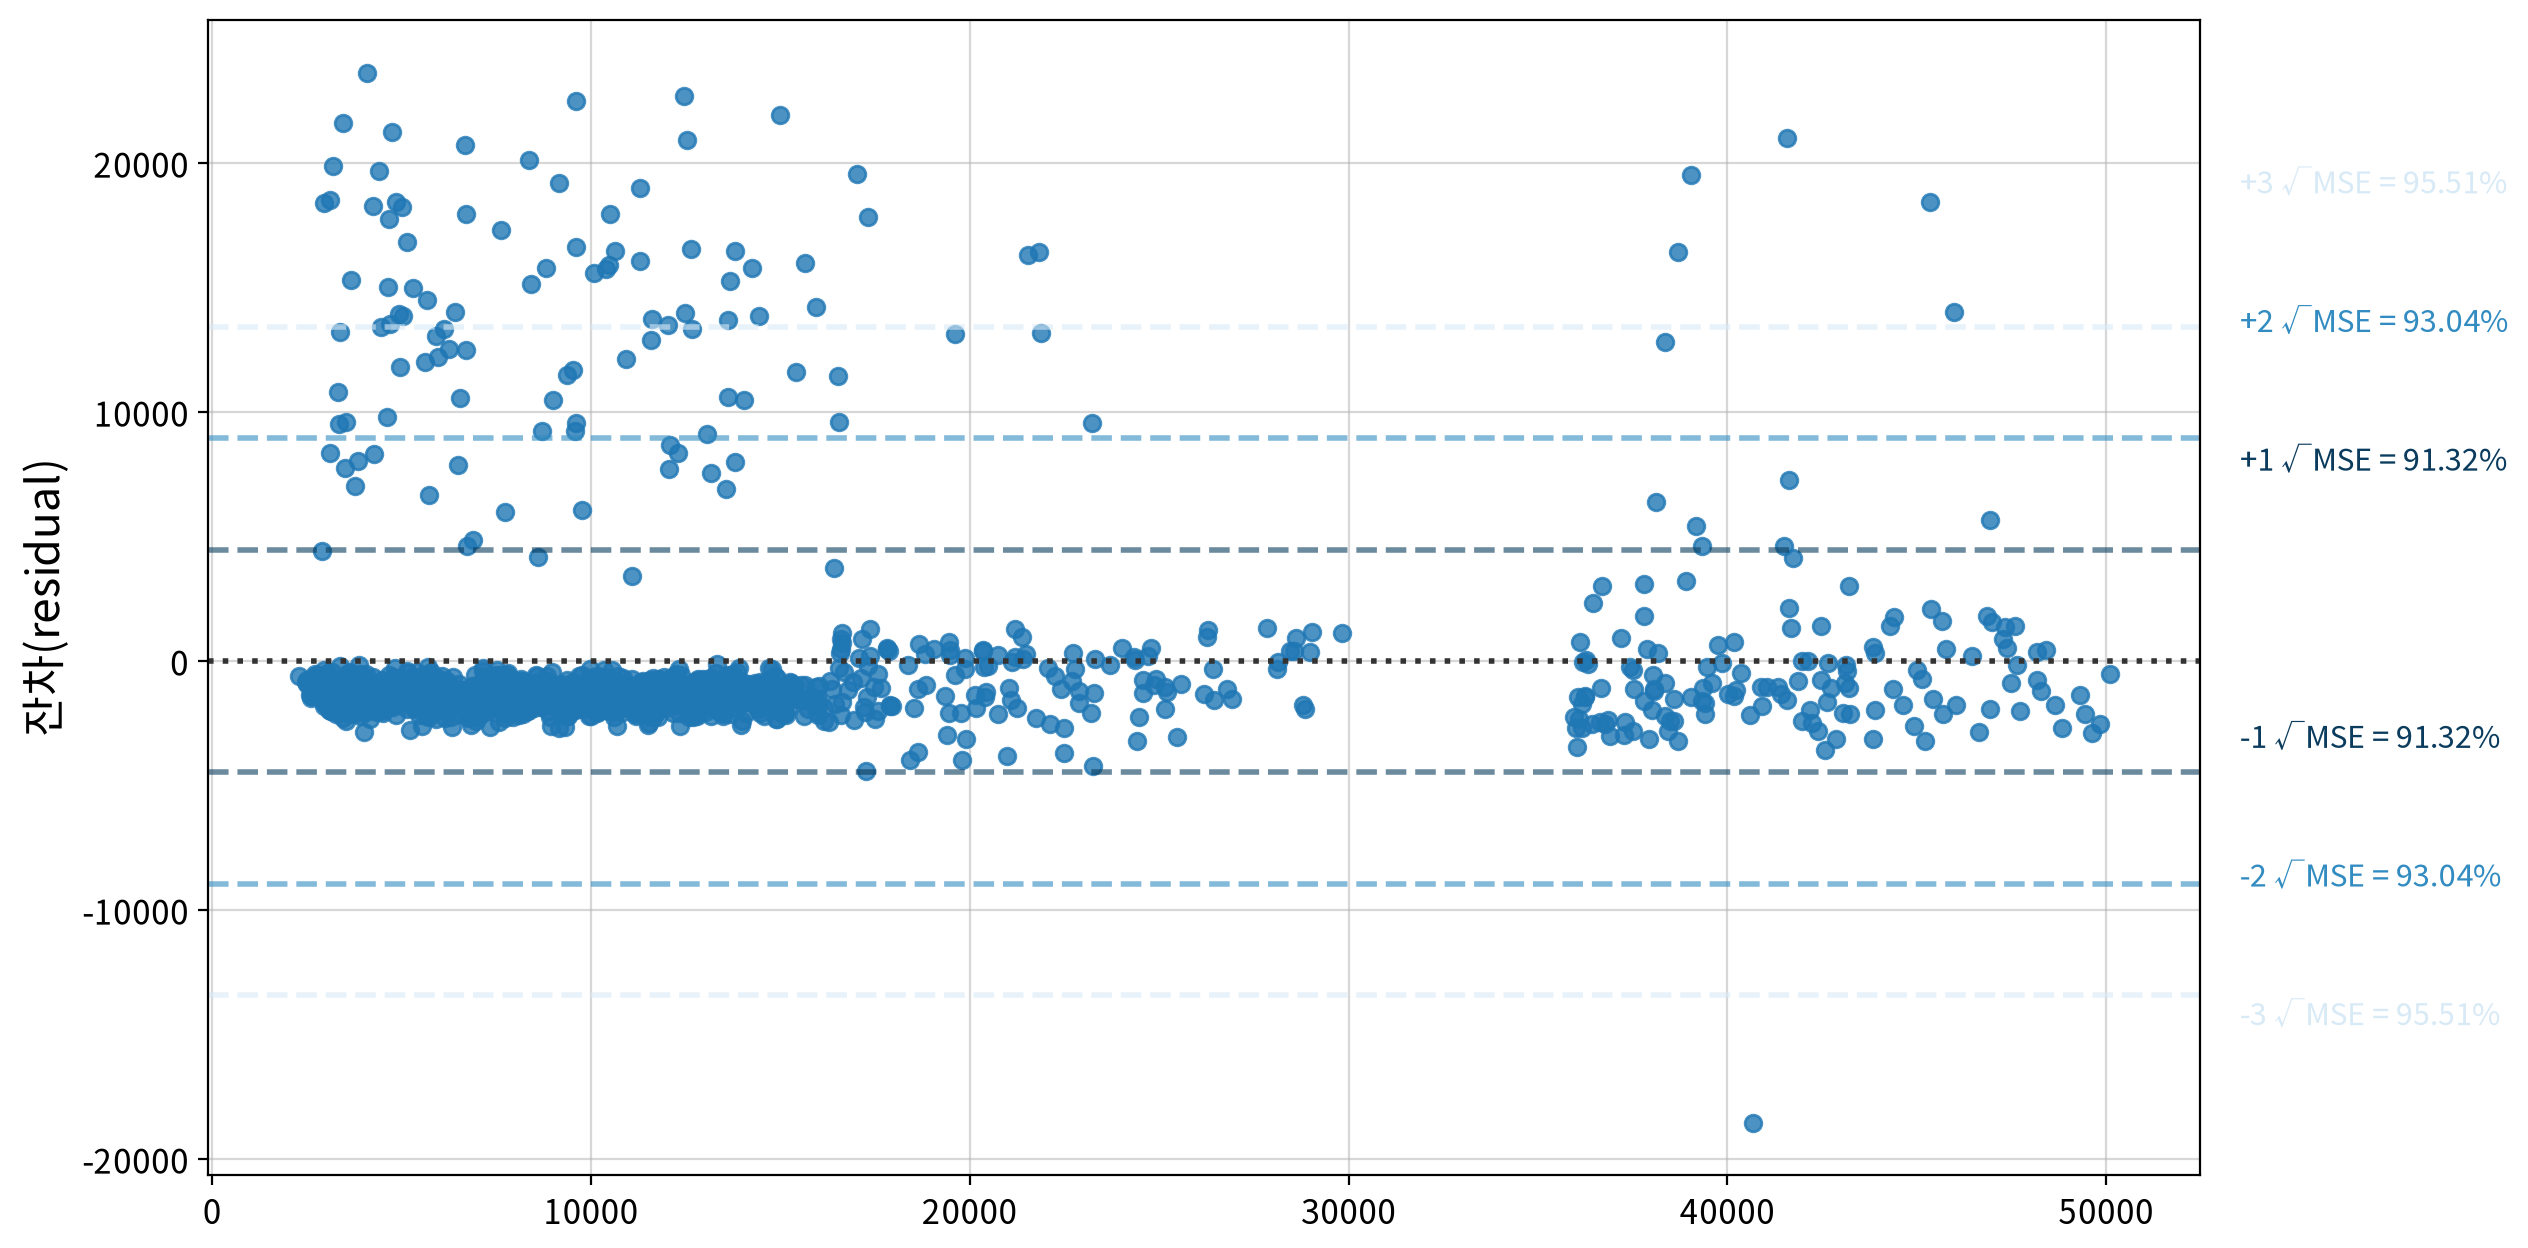

#### 3) 등분산성 검정

,LM Statistic,LM p-value,F Statistic,F p-value,homoscedasticity
Breusch-Pagan,2.038,0.844,0.406,0.845,True


F p-value = 0.8445 · 등분산성 판정: 귀무가설 채택 → 등분산성 만족



#### 4) 독립성 검정

,statistic,independence,result
Durbin-Watson,2.066,True,독립성 만족


In [103]:
my_ols.report_model(final_fit)

> 💡 **인사이트 — 최종 모델**
>
> - **F(5, 1331) = 1,690.0, p < .001, R² = 0.864** — 청구비용 변동의 86.4%를 설명한다.
> - 영향력 순위(β): **`smoker_obese`(0.497)** > `smoker`(0.454) > `age2`(0.310) > `children`(0.065) > `bmi`(0.023)
> - 계수 해석:
>   - 흡연자는 기본적으로 **+13,606달러**, 거기에 비만이면 **+19,338달러가 추가**된다 (흡연·비만 합계 약 +32,944달러).
>   - 나이 효과는 `3.34 × age²` → 30세→40세는 약 +2,300달러, 50세→60세는 약 +3,700달러로 **나이가 들수록 증가 폭이 커진다.**
>   - `bmi` 자체의 효과는 1당 46달러로 미미하다. **BMI의 위험은 흡연과 결합할 때 크게 드러난다.**
> - **가정 검정이 크게 개선됐다.** 기준선 모델에서 위배됐던 **선형성(RESET p = 0.782)과 등분산성(BP p = 0.845)이 모두 충족**됐고 독립성(DW = 2.066)도 충족이다. 구조를 제대로 잡자 가정 위배가 '증상'처럼 사라진 것이다. 남은 것은 정규성 위배뿐이다.

---

# 📌 종합 인사이트

### 1. 청구비용을 결정하는 것은 '흡연', 그리고 '흡연 × 비만'이다
- 흡연자는 비흡연자보다 기본 +13,606달러, **비만까지 겹치면 +32,944달러**를 더 청구한다.
- 비흡연자에게 비만은 +879달러(+11%)에 불과하지만 **흡연자에게는 +20,195달러(+95%)** 다. 두 위험요인은 더해지는 것이 아니라 **곱해진다.**

### 2. 기계적 전처리보다 '데이터 구조를 읽는 것'이 더 큰 성과를 냈다
| 접근 | 최고 RMSE | R² |
|---|---|---|
| 기계적 전처리 5단계 (로그·이상치·VIF·스케일링) | 6,059 (기준선) | 0.750 |
| **EDA 기반 파생변수 2개** | **4,466** | **0.864** |
- 로그변환은 오히려 RMSE를 37% 악화시켰다. 문제는 '치우친 분포'가 아니라 **'섞여 있는 집단'** 이었기 때문이다.
- 상호작용항을 넣자 **선형성 · 등분산성 위배가 함께 해소**됐다. 가정 위배는 모델 구조가 틀렸다는 신호였다.

### 3. 성별·지역은 요율 근거가 되지 못한다
- `sex`(p = 0.695), `region`(p = 0.053, 효과크기 무시 수준)은 EDA 단계에서 제외했다.

### ⚠️ 한계
- 성능은 **학습 데이터 기준(in-sample)** 이다. 실제 예측력은 train/test 분할이나 교차검증으로 확인해야 한다.
- 비만 경계(BMI 30)는 WHO 기준을 따른 것으로, 경계를 바꾸면 `smoker_obese`의 효과 크기가 달라질 수 있다.
- 잔차의 정규성이 위배됐다. 흡연·비만·나이로 설명되지 않는 고비용 가입자가 남아 있다는 뜻으로, 병력·사고 이력 등 데이터에 없는 요인일 가능성이 있다.

### ✅ 최종 모델
| 항목 | 값 |
|---|---|
| 형태 | `charges` ~ `smoker` + `smoker_obese` + `age²` + `children` + `bmi` |
| 성능 | **RMSE 4,466** · MAE 2,447 · R² 0.864 |
| 가정 | 선형성 ✅ · 등분산성 ✅ · 독립성 ✅ · 정규성 ❌ |
| 가장 큰 영향 | `smoker_obese` (β = 0.497) |